# 04 – The first model: orthogonal-factor linear regression
**AI factor lens project – model layer, version 1**

For every AI-basket stock, layer basket and the overall baskets this notebook fits

`excess return_t = α + β_MKT·MKT_t + γ_2·z_2,t + … + γ_K·z_K,t + ε_t`

where `z_2 … z_K` are the **sequentially orthogonalised** factors (Gram–Schmidt in a fixed economic order: market first,
then macro, then style, …). Orthogonal factors make every statement additive: the variance of a stock splits *exactly*
into factor shares plus a residual share, and the return of any day or month splits exactly into factor contributions.

**What it produces**
1. **Static model** (estimation window): exposures with Newey–West t-statistics, R², out-of-sample R² in the holdout,
   parameter-shift tests (estimation → holdout), residual diagnostics.
2. **Rolling model** (252-day sliding window, re-estimated every day): time-varying exposures; fully **causal** – the
   orthogonalisation and the coefficients used on day *t* only use data up to *t−1*.
3. **Out-of-sample evaluation** of the rolling model against a market-only baseline and the next models (M2, M3), with
   block-bootstrap confidence intervals.
4. **Attribution – “what drove performance and risk this month?”**: daily contributions of RF, each factor, alpha and
   residual (they add up to the actual return *exactly*), linked to months with Carino linking, plus variance shares.

**The models** (nested; edit `MODELS`): `M0` market only (baseline) → `M1_non_AI` (the first, AI-blind model) →
`M2_plus_adjacent` (power / grid / uranium) → `M3_plus_AI_close` (SEMI, SOFT, ROBO, MOM). Everything is computed for all
of them; the attribution and detail tables are printed for `PRIMARY_MODEL`.

**Honest limits.** A linear factor model explains co-movement, not causation. The factors are ETF spreads, so some hold
the very stocks being explained (see notebook 03's overlap analysis); M1 avoids that on purpose.

## 1. Configuration

In [1]:
import os, sys, json, hashlib, platform, zlib, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

try:
    display
except NameError:                      # plain python (tests); notebooks provide display()
    display = print

# ---- where things live --------------------------------------------------------------------------------
DRIVE_BASE     = "/content/drive/MyDrive/factor_lens"
RAW_VERSION    = "yahoo_2016-01-01_2026-10-01_v1"
CLEAN_VERSION  = "clean_v1"
FACTOR_VERSION = "factors_v1"          # notebook 03 output that holds factors_raw / baskets / basket_members
MODEL_VERSION  = "model_v1"

# ---- windows (same split as notebook 03) --------------------------------------------------------------
EST_START,  EST_END  = "2017-01-03", "2023-12-29"
HOLD_START, HOLD_END = "2024-01-02", "2026-10-01"

FORCE_RECOMPUTE = False
SHOW_FIGURES    = True
CODE_VERSION    = "r5"

# ---- the models: factor ORDER matters for orthogonalisation (earlier factors are removed from later ones) --------
MODELS = {
    "M0_market_only":   ["MKT"],
    "M1_non_AI":        ["MKT", "D10Y", "USD", "OIL", "LOWVOL"],
    "M2_plus_adjacent": ["MKT", "D10Y", "USD", "OIL", "LOWVOL", "POWER", "GRID", "URANIUM"],
    "M3_plus_AI_close": ["MKT", "D10Y", "USD", "OIL", "LOWVOL", "POWER", "GRID", "URANIUM", "SEMI", "SOFT", "ROBO", "MOM"],
}
# Basket layers whose stocks are (largely) HELD by a factor's ETFs (approximate; same map as notebook 03). Used to build the
# overlap-free yardstick baskets: ALL_core without the layers held by the model's own factors.
OVERLAP = {
    "SEMI": ["compute_chips"], "ROBO": ["compute_chips"], "SOFT": ["hyperscalers_software"], "CLOUD": ["hyperscalers_software"],
    "INFRA": ["datacenter_neocloud"], "UTIL": ["power_generation"], "POWER": ["power_generation"],
    "GRID": ["grid_electrical"], "CAPEX": ["grid_electrical"], "URANIUM": ["nuclear_uranium"],
}
PRIMARY_MODEL = "M1_non_AI"
BASELINE_MODEL = "M0_market_only"
REPORT_MONTHS = None        # e.g. ["2026-07", "2026-08", "2026-09"]; None = the last 3 complete months

# Pre-declared validation samples for the AI-factor placebo test.  The close names are economically
# AI-exposed; controls span unrelated, mature sectors and are not inputs to the factor construction.
AI_CLOSE_TEST_STOCKS = ['NVDA', 'AVGO', 'MSFT', 'AMZN', 'GOOGL', 'META', 'ORCL']
NON_AI_CONTROL_STOCKS = ['KO', 'PG', 'WMT', 'MCD', 'JNJ', 'JPM', 'XOM', 'CAT']

CFG = dict(
    window=252,               # sliding-window length (trading days)
    min_rows=200,             # minimum complete factor rows in a window
    min_obs_target=200,       # minimum valid target observations in a window
    nw_lags=5,                # Newey-West lags
    lb_lags=10, arch_lags=5,  # residual diagnostics
    boot_B=500, boot_block=20, boot_seed=2026, ci_level=0.95,
    shift_z=2.0,              # |z| above this flags a parameter shift (estimation -> holdout)
    min_effect=0.01,          # an R2 increment needs |delta| >= this AND a CI excluding 0 to be starred
    top_n=8,
    min_total_vol=0.15,       # annualised volatility below this over the estimation window => flagged as a suspect (shell / non-trading) history
)

## 2. Helpers: paths, inputs, targets

In [2]:
def mount_drive():
    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive")
        return Path(DRIVE_BASE)
    return Path(os.environ.get("FACTOR_LENS_LOCAL", "./factor_lens_local"))


def load_inputs(base):
    clean_root = base / "clean" / f"{CLEAN_VERSION}__{RAW_VERSION}"
    fac_root = base / "factors" / f"{FACTOR_VERSION}__{CLEAN_VERSION}__{RAW_VERSION}"
    d = {}
    d["F"] = pd.read_parquet(fac_root / "factors_raw.parquet")
    d["B"] = pd.read_parquet(fac_root / "baskets.parquet")
    d["members"] = pd.read_parquet(fac_root / "basket_members.parquet")
    d["rx"] = pd.read_parquet(clean_root / "returns_excess.parquet")
    d["rf"] = pd.read_parquet(clean_root / "rf_daily.parquet")["rf_daily"]
    for k in ("F", "B", "rx"):
        d[k].index = pd.DatetimeIndex(d[k].index)
        d[k] = d[k].sort_index()
    d["rf"].index = pd.DatetimeIndex(d["rf"].index)
    d["keys"] = (json.loads((clean_root / "done.json").read_text()).get("key", ""),
                 json.loads((fac_root / "done.json").read_text()).get("key", ""))
    d["fac_root"] = fac_root
    return d


def build_targets(inp):
    """Model the AI baskets, their members, and pre-declared non-AI placebo controls."""
    B, rx, mem = inp["B"], inp["rx"], inp["members"]
    basket_stocks = [t for t in mem.loc[mem["in_data"].astype(bool), "ticker"].tolist() if t in rx.columns]
    controls = [t for t in NON_AI_CONTROL_STOCKS if t in rx.columns]
    stocks = list(dict.fromkeys(basket_stocks + controls))
    layer = mem.drop_duplicates("ticker").set_index("ticker")["layer"].to_dict()
    layer.update({t: "non_AI_control" for t in controls})
    core = mem.drop_duplicates("ticker").set_index("ticker")["core"].astype(bool).to_dict()
    yard = {}
    for m, facs in MODELS.items():                    # overlap-free yardstick: ALL_core without the layers the model's factors hold
        ov = sorted({l for f in facs for l in OVERLAP.get(f, [])})
        if not ov:
            continue
        names = [t for t in stocks if core.get(t, False) and layer.get(t, "") not in ov]
        if len(names) >= 2:
            sub = rx[names].reindex(B.index)
            yard[f"ALL_core_ex_{m.split('_')[0]}_overlap"] = sub.mean(axis=1).where(sub.notna().sum(axis=1) >= 2)
    # Equal-weight validation portfolios make the AI-vs-control comparison less noisy than one stock.
    test_baskets = {}
    for name, names in [("AI_close_test", AI_CLOSE_TEST_STOCKS), ("non_AI_control_test", NON_AI_CONTROL_STOCKS)]:
        names = [t for t in names if t in rx.columns]
        if len(names) >= 3:
            sub = rx[names].reindex(B.index)
            test_baskets[name] = sub.mean(axis=1).where(sub.notna().sum(axis=1) >= 3)
    Bx = pd.concat([B, pd.DataFrame(yard, index=B.index), pd.DataFrame(test_baskets, index=B.index)], axis=1)
    Y = pd.concat([Bx, rx[stocks].reindex(B.index)], axis=1)
    kind = pd.Series(["basket"] * Bx.shape[1] + ["stock"] * len(stocks), index=Y.columns)
    lay = pd.Series([c if c in Bx.columns else layer.get(c, "") for c in Y.columns], index=Y.columns)
    return Y, kind, lay

## 3. The engine: sequential orthogonalisation and OLS
- `gs_transform`: Gram–Schmidt on a window of (centred) factors → orthogonal columns `Z`, and `Phi` (how each factor is
  built from the earlier orthogonal ones). `apply_transform` applies the SAME transformation to new days (causal use).
- With orthogonal `Z`, OLS coefficients are `γ_k = <z_k, y>/<z_k, z_k>` and the variance shares `γ_k·cov(z_k, y)/var(y)`
  add up to R² exactly (this identity holds for any OLS fit with an intercept).
- The market enters the attribution **raw** (its premium belongs to the market), later factors as orthogonalised
  residuals; the intercept `α'` is expressed in that basis.

In [3]:
def gs_transform(Xc):
    """Xc: W x K centred factors. Returns Z (orthogonal columns), Phi (K x K, Phi[k, j] for j < k), ss (column sums of squares)."""
    W, K = Xc.shape
    Z = np.empty_like(Xc)
    Phi = np.zeros((K, K))
    ss = np.empty(K)
    for k in range(K):
        v = Xc[:, k].copy()
        for j in range(k):
            Phi[k, j] = (Xc[:, k] @ Z[:, j]) / ss[j]
            v -= Phi[k, j] * Z[:, j]
        Z[:, k] = v
        ss[k] = v @ v
    return Z, Phi, ss


def apply_transform(X, mu, Phi):
    """Apply a window's orthogonalisation to new rows X (T x K, raw factor returns)."""
    Z = np.array(X, dtype=float, copy=True) - mu
    K = Z.shape[1]
    for k in range(K):
        for j in range(k):
            Z[:, k] -= Phi[k, j] * Z[:, j]
    return Z


def fit_window(Fw, Yw, min_rows, min_obs_t):
    """OLS of every target on the orthogonalised factors of ONE window. Returns a dict of arrays or None."""
    ok = ~np.isnan(Fw).any(axis=1)
    n_ok = int(ok.sum())
    if n_ok < min_rows:
        return None
    X = Fw[ok]
    mu = X.mean(0)
    Z, Phi, ss = gs_transform(X - mu)
    Y = Yw[ok]
    mask = ~np.isnan(Y)
    N, K = Y.shape[1], X.shape[1]
    nan_ = lambda *s: np.full(s, np.nan)
    gamma, share = nan_(N, K), nan_(N, K)
    alpha, r2, rvar, ybar = nan_(N), nan_(N), nan_(N), nan_(N)
    nobs = mask.sum(0).astype(float)
    full = mask.all(axis=0)
    if full.any():
        Yf = Y[:, full]
        yb = Yf.mean(0)
        Yc = Yf - yb
        zy = Z.T @ Yc
        g = (zy / ss[:, None]).T
        resid = Yc - Z @ g.T
        sse, sst = (resid ** 2).sum(0), (Yc ** 2).sum(0)
        gamma[full], ybar[full] = g, yb
        alpha[full] = yb - g[:, 0] * mu[0]
        r2[full], rvar[full] = 1.0 - sse / sst, sse / (n_ok - 1)
        share[full] = g * (zy.T / (n_ok - 1)) / (sst / (n_ok - 1))[:, None]
    for j in np.where(~full & (nobs >= min_obs_t))[0]:
        m = mask[:, j]
        yj, Zj = Y[m, j], Z[m]
        nj = len(yj)
        zb, yb = Zj.mean(0), yj.mean()
        g = np.linalg.lstsq(Zj - zb, yj - yb, rcond=None)[0]
        resid = (yj - yb) - (Zj - zb) @ g
        sse, sst = resid @ resid, ((yj - yb) ** 2).sum()
        gamma[j], ybar[j] = g, yb
        alpha[j] = (yb - zb @ g) - g[0] * mu[0]
        r2[j], rvar[j] = 1.0 - sse / sst, sse / (nj - 1)
        share[j] = g * (((Zj - zb).T @ (yj - yb)) / (nj - 1)) / (sst / (nj - 1))
    thin = nobs < min_obs_t
    for a in (gamma, share):
        a[thin] = np.nan
    for a in (alpha, r2, rvar, ybar):
        a[thin] = np.nan
    return dict(gamma=gamma, alpha=alpha, r2=r2, rvar=rvar, ybar=ybar, nobs=nobs, share=share, mu=mu, Phi=Phi,
                zsd=np.sqrt(ss / (n_ok - 1)))


def rolling_fit(Fv, Yv, window, min_rows, min_obs_t):
    T, K = Fv.shape
    N = Yv.shape[1]
    out = dict(gamma=np.full((T, N, K), np.nan), share=np.full((T, N, K), np.nan), alpha=np.full((T, N), np.nan),
               r2=np.full((T, N), np.nan), rvar=np.full((T, N), np.nan), ybar=np.full((T, N), np.nan),
               nobs=np.full((T, N), np.nan), mu=np.full((T, K), np.nan), Phi=np.full((T, K, K), np.nan), zsd=np.full((T, K), np.nan))
    for i in range(window - 1, T):
        res = fit_window(Fv[i - window + 1:i + 1], Yv[i - window + 1:i + 1], min_rows, min_obs_t)
        if res is None:
            continue
        for k, v in res.items():
            out[k][i] = v
    return out


def causal_attribution(Fv, Yv, roll):
    """Day t is explained with parameters from the window ending t-1. Residual = actual - fitted (so everything adds up)."""
    T, K = Fv.shape
    N = Yv.shape[1]
    C = np.full((T, N, K), np.nan)
    alpha_t = np.full((T, N), np.nan)
    for t in range(1, T):
        i = t - 1
        if np.isnan(roll["mu"][i, 0]) or np.isnan(Fv[t]).any():
            continue
        z = apply_transform(Fv[t][None, :], roll["mu"][i], roll["Phi"][i])[0]
        z[0] = Fv[t, 0]                                   # the market enters raw
        C[t] = roll["gamma"][i] * z[None, :]
        alpha_t[t] = roll["alpha"][i]
    fitted = alpha_t + C.sum(axis=2)
    return dict(C=C, alpha=alpha_t, fitted=fitted, resid=Yv - fitted)


def fitted_from_params(par, Fv):
    """Apply ONE fitted window (static model) to rows Fv. Returns fitted (T x N), contributions (T x N x K)."""
    Z = apply_transform(Fv, par["mu"], par["Phi"])
    Z[:, 0] = Fv[:, 0]
    C = par["gamma"][None, :, :] * Z[:, None, :]
    return par["alpha"][None, :] + C.sum(axis=2), C

## 4. Inference: Newey–West, shift tests, residual diagnostics

In [4]:
def nw_multi(y, X, lags):
    """OLS of y on X (X already includes the constant) with Newey-West (Bartlett) covariance. Returns beta, se."""
    n = len(y)
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ (X.T @ y)
    u = y - X @ b
    Zm = X * u[:, None]
    S = Zm.T @ Zm
    for l in range(1, lags + 1):
        G = Zm[l:].T @ Zm[:-l]
        S = S + (1.0 - l / (lags + 1.0)) * (G + G.T)
    cov = XtX_inv @ S @ XtX_inv
    return b, np.sqrt(np.diag(cov))


def ljung_box(e, m):
    e = e - e.mean()
    n = len(e)
    ac = np.array([(e[k:] @ e[:-k]) / (e @ e) for k in range(1, m + 1)])
    q = n * (n + 2) * np.sum(ac ** 2 / (n - np.arange(1, m + 1)))
    return float(q), float(1.0 - stats.chi2.cdf(q, m))


def arch_lm(e, m):
    e2 = e ** 2
    n = len(e2)
    Y = e2[m:]
    X = np.column_stack([np.ones(n - m)] + [e2[m - k:n - k] for k in range(1, m + 1)])
    b = np.linalg.lstsq(X, Y, rcond=None)[0]
    r2 = 1.0 - ((Y - X @ b) ** 2).sum() / ((Y - Y.mean()) ** 2).sum()
    lm = (n - m) * r2
    return float(lm), float(1.0 - stats.chi2.cdf(lm, m))


def durbin_watson(e):
    return float(np.sum(np.diff(e) ** 2) / np.sum(e ** 2))

## 5. Static model (estimation window)

In [5]:
def sl(df, a, b):
    return df.loc[a:b]


def static_model(F, Y, factors, kind, lay):
    """Fit on the estimation window; evaluate on the holdout with the estimation coefficients; test parameter shifts."""
    Fe, Fh = sl(F[factors], EST_START, EST_END), sl(F[factors], HOLD_START, HOLD_END)
    Ye, Yh = sl(Y, EST_START, EST_END), sl(Y, HOLD_START, HOLD_END)
    par = fit_window(Fe.to_numpy(float), Ye.to_numpy(float), CFG["min_rows"], CFG["min_obs_target"])
    K, N = len(factors), Y.shape[1]
    okE = ~np.isnan(Fe.to_numpy(float)).any(1)
    ZE = apply_transform(Fe.to_numpy(float)[okE], par["mu"], par["Phi"])
    ok_h = ~np.isnan(Fh.to_numpy(float)).any(1)
    Zh = apply_transform(Fh.to_numpy(float)[ok_h], par["mu"], par["Phi"])
    XE, Xh = Fe.to_numpy(float)[okE], Fh.to_numpy(float)[ok_h]
    coef_rows, fit_rows, shift_rows, diag_rows = [], [], [], []
    Yev, Yhv = Ye.to_numpy(float)[okE], Yh.to_numpy(float)[ok_h]
    fit_e, _ = fitted_from_params(par, Fe.to_numpy(float)[okE])
    fit_h, _ = fitted_from_params(par, Xh)
    for n, tgt in enumerate(Y.columns):
        ye, yh = Yev[:, n], Yhv[:, n]
        me, mh = ~np.isnan(ye), ~np.isnan(yh)
        if me.sum() < CFG["min_obs_target"] or np.isnan(par["r2"][n]):
            continue
        # orthogonal-basis inference (gamma) and raw-basis inference (classic OLS coefficients)
        Xz = np.column_stack([np.ones(me.sum()), ZE[me]])
        bz, sez = nw_multi(ye[me], Xz, CFG["nw_lags"])
        Xr = np.column_stack([np.ones(me.sum()), XE[me]])
        br, ser = nw_multi(ye[me], Xr, CFG["nw_lags"])
        e_res = ye[me] - (Xz @ bz)
        for k, f in enumerate(factors):
            coef_rows.append(dict(target=tgt, factor=f, gamma=bz[1 + k], t_gamma=bz[1 + k] / sez[1 + k], raw_beta=br[1 + k],
                                  t_raw=br[1 + k] / ser[1 + k], effect_1sd_bp=bz[1 + k] * par["zsd"][k] * 1e4,
                                  var_share=par["share"][n, k], held=bool(lay[tgt] in OVERLAP.get(f, []))))
        # holdout: out-of-sample (estimation coefficients) and re-fit with the SAME orthogonalisation
        r2_oos = r2_hold_refit = np.nan
        if mh.sum() >= 50:
            sse = ((yh[mh] - fit_h[mh, n]) ** 2).sum()
            r2_oos = 1.0 - sse / ((yh[mh] - par["ybar"][n]) ** 2).sum()
            Xzh = np.column_stack([np.ones(mh.sum()), Zh[mh]])
            bh, seh = nw_multi(yh[mh], Xzh, CFG["nw_lags"])
            res_h = yh[mh] - Xzh @ bh
            r2_hold_refit = 1.0 - (res_h ** 2).sum() / ((yh[mh] - yh[mh].mean()) ** 2).sum()
            for k, f in enumerate(factors):
                z = (bh[1 + k] - bz[1 + k]) / np.sqrt(sez[1 + k] ** 2 + seh[1 + k] ** 2)
                shift_rows.append(dict(target=tgt, factor=f, gamma_est=bz[1 + k], gamma_hold=bh[1 + k], z_shift=z,
                                       shifted=bool(abs(z) > CFG["shift_z"])))
        n_obs = int(me.sum())
        adj = 1.0 - (1.0 - par["r2"][n]) * (n_obs - 1) / (n_obs - K - 1)
        tot_vol = float(np.std(ye[me], ddof=1) * np.sqrt(252))
        fit_rows.append(dict(target=tgt, kind=kind[tgt], layer=lay[tgt], n_est=n_obs, r2_est=par["r2"][n], adj_r2_est=adj,
                             resid_vol_ann=float(np.sqrt(par["rvar"][n] * 252)), total_vol_ann=tot_vol, r2_oos_hold=r2_oos,
                             r2_hold_refit=r2_hold_refit, alpha_ann=float(par["alpha"][n] * 252),
                             flag="low-volatility history (SPAC shell / non-trading?) - do not trust" if (kind[tgt] == "stock" and tot_vol < CFG["min_total_vol"]) else ""))
        diag_rows.append(dict(target=tgt, kind=kind[tgt], n=n_obs, dw=durbin_watson(e_res),
                              lb_p=ljung_box(e_res, CFG["lb_lags"])[1], lb_sq_p=ljung_box(e_res ** 2, CFG["lb_lags"])[1],
                              arch_p=arch_lm(e_res, CFG["arch_lags"])[1],
                              jb_p=float(stats.jarque_bera(e_res).pvalue), resid_skew=float(stats.skew(e_res)),
                              resid_ex_kurt=float(stats.kurtosis(e_res))))
    tr = pd.DataFrame(par["Phi"], index=factors, columns=factors)
    tr.insert(0, "mean", par["mu"])
    tr["z_std"] = par["zsd"]
    return dict(coef=pd.DataFrame(coef_rows), fit=pd.DataFrame(fit_rows), shift=pd.DataFrame(shift_rows),
                diag=pd.DataFrame(diag_rows), transform=tr.reset_index().rename(columns={"index": "factor"}), par=par)

## 6. Out-of-sample evaluation of the rolling models (with block-bootstrap intervals)
The benchmark forecast is the trailing-window mean of the target (a standard "historical mean" benchmark):
`R²_oos = 1 − Σ e² / Σ (y − ȳ_window)²`. Every model is evaluated on the SAME days. Intervals: circular block bootstrap
of days, identical resampled days for every model, so differences are paired.

In [6]:
def _block_idx(T, block, rng):
    nb = int(np.ceil(T / block))
    starts = rng.integers(0, T, nb)
    return ((starts[:, None] + np.arange(block)[None, :]).ravel() % T)[:T]


def periods(dates):
    first = dates[0]
    return {"pre_holdout": (first, pd.Timestamp(EST_END)), "holdout": (pd.Timestamp(HOLD_START), pd.Timestamp(HOLD_END)),
            "all": (first, pd.Timestamp(HOLD_END))}


def oos_tables(Yv, dates, targets, e2, hist_mean, models):
    """e2: dict model -> (T x N) squared errors; Returns long table with R2_oos, CI, and paired differences vs the previous model."""
    sst = (Yv - hist_mean) ** 2
    valid_all = np.all([~np.isnan(e2[m]) for m in models], axis=0) & ~np.isnan(sst)
    first_valid = np.where(valid_all.any(axis=1))[0]
    pers = periods(dates[first_valid]) if len(first_valid) else {}
    rows = []
    a = (1.0 - CFG["ci_level"]) / 2.0
    for pname, (p0, p1) in pers.items():
        in_p = np.asarray((dates >= p0) & (dates <= p1))
        for n, tgt in enumerate(targets):
            idx = np.where(valid_all[:, n] & in_p)[0]
            if len(idx) < 60:
                continue
            S = sst[idx, n]
            E = {m: e2[m][idx, n] for m in models}
            point = {m: 1.0 - E[m].sum() / S.sum() for m in models}
            rng = np.random.default_rng([CFG["boot_seed"], zlib.crc32(tgt.encode()) % (2 ** 31), zlib.crc32(pname.encode()) % (2 ** 31)])
            B = CFG["boot_B"]
            draws = np.zeros((B, len(models)))
            for b in range(B):
                ii = _block_idx(len(idx), CFG["boot_block"], rng)
                s_ = S[ii].sum()
                for k, m in enumerate(models):
                    draws[b, k] = 1.0 - E[m][ii].sum() / s_
            for k, m in enumerate(models):
                lo, hi = np.percentile(draws[:, k], [100 * a, 100 * (1 - a)])
                row = dict(period=pname, target=tgt, model=m, n_days=len(idx), r2_oos=point[m], lo=lo, hi=hi)
                if k > 0:
                    d = draws[:, k] - draws[:, k - 1]
                    dlo, dhi = np.percentile(d, [100 * a, 100 * (1 - a)])
                    dp = point[m] - point[models[k - 1]]
                    row.update(vs=models[k - 1], delta=dp, d_lo=dlo, d_hi=dhi,
                               sig=bool((dlo > 0 or dhi < 0) and abs(dp) >= CFG["min_effect"]))
                rows.append(row)
    return pd.DataFrame(rows)

## 7. Attribution: daily → monthly (Carino linking) and variance shares
Daily total return `r = y + rf` splits as `RF + ALPHA + Σ_k factor_k + RESIDUAL` (exact). A month's compounded return is
split with **Carino linking**: each day's components are scaled by `[ln(1+r_t)/r_t] / [ln(1+R)/R]`, so the monthly
contributions add up to the monthly return exactly. Risk shares come from the window ending at the month-end (ex-post)
and at the previous month-end (ex-ante).

In [7]:
def carino_link(comp, r):
    """comp: (days x components) daily contributions that sum to r; returns the linked month contribution vector."""
    R = float(np.prod(1.0 + r) - 1.0)
    kt = np.where(np.abs(r) < 1e-12, 1.0, np.log1p(r) / np.where(np.abs(r) < 1e-12, 1.0, r))
    K = 1.0 if abs(R) < 1e-12 else np.log1p(R) / R
    return (kt[:, None] / K * comp).sum(axis=0), R


def monthly_attribution(attr, Yv, rf_v, dates, targets, factors, tindex):
    """Returns a long table: month, target, component, contribution (linked), total_return."""
    C, alpha, resid = attr["C"], attr["alpha"], attr["resid"]
    comps = ["RF", "ALPHA"] + factors + ["RESIDUAL"]
    months = pd.PeriodIndex(dates, freq="M")
    rows = []
    for n, tgt in enumerate(targets):
        ok = ~np.isnan(C[:, n, :]).any(axis=1) & ~np.isnan(Yv[:, n]) & ~np.isnan(rf_v)
        if not ok.any():
            continue
        comp = np.column_stack([rf_v, alpha[:, n], C[:, n, :], resid[:, n]])
        r = Yv[:, n] + rf_v
        for m in months[ok].unique():
            sel = ok & (months == m)
            if sel.sum() < 5:
                continue
            lin, R = carino_link(comp[sel], r[sel])
            row = dict(month=str(m), target=tgt, total_return=R, n_days=int(sel.sum()))
            row.update({c: v for c, v in zip(comps, lin)})
            row["SPECIFIC"] = row["ALPHA"] + row["RESIDUAL"]          # the part no factor explains (trailing drift + surprise)
            rows.append(row)
    return pd.DataFrame(rows)


def risk_monthly(roll, dates, targets, factors):
    months = pd.PeriodIndex(dates, freq="M")
    rows = []
    last_idx = pd.Series(np.arange(len(dates)), index=months).groupby(level=0).max()
    for m, i in last_idx.items():
        if np.isnan(roll["r2"][i]).all():
            continue
        for n, tgt in enumerate(targets):
            if np.isnan(roll["r2"][i, n]):
                continue
            vol = float(np.sqrt(((roll["rvar"][i, n]) / (1.0 - roll["r2"][i, n])) * 252))
            for k, f in enumerate(factors):
                rows.append(dict(month=str(m), target=tgt, component=f, share=roll["share"][i, n, k], vol_ann=vol))
            rows.append(dict(month=str(m), target=tgt, component="RESIDUAL", share=1.0 - roll["r2"][i, n], vol_ann=vol))
    return pd.DataFrame(rows)

## 8. Run everything

In [8]:
def run_models(inp):
    F, rx, rf = inp["F"], inp["rx"], inp["rf"]
    Y, kind, lay = build_targets(inp)
    idx = F.index.union(Y.index)
    F, Y = F.reindex(idx), Y.reindex(idx)
    rf_v = rf.reindex(idx).ffill(limit=3).to_numpy(float)
    dates = idx
    targets = list(Y.columns)
    Yv = Y.to_numpy(float)
    R = {}
    hist_mean = Y.rolling(CFG["window"], min_periods=CFG["min_obs_target"]).mean().shift(1).to_numpy(float)

    missing = {m: [f for f in fs if f not in F.columns] for m, fs in MODELS.items()}
    for m, miss in missing.items():
        if miss:
            raise KeyError(f"model {m}: factors not found in factors_raw: {miss} (eligible in notebook 03?)")

    rolls, attrs, e2, statics, fits = {}, {}, {}, {}, []
    for m, facs in MODELS.items():
        Fv = F[facs].to_numpy(float)
        rolls[m] = rolling_fit(Fv, Yv, CFG["window"], CFG["min_rows"], CFG["min_obs_target"])
        attrs[m] = causal_attribution(Fv, Yv, rolls[m])
        e2[m] = attrs[m]["resid"] ** 2
        statics[m] = static_model(F, Y, facs, kind, lay)
        f_ = statics[m]["fit"].copy()
        f_.insert(0, "model", m)
        fits.append(f_)
    R["static_fit_all"] = pd.concat(fits, ignore_index=True)

    pm = PRIMARY_MODEL
    st = statics[pm]
    R["static_coef"], R["static_fit"], R["static_shift"], R["static_diag"], R["static_transform"] = st["coef"], st["fit"], st["shift"], st["diag"], st["transform"]
    corr = F[MODELS[pm]].loc[EST_START:EST_END].dropna().corr()
    R["factor_corr_raw"] = corr
    R["factor_vif_raw"] = pd.Series(np.diag(np.linalg.inv(corr.to_numpy())), index=corr.index, name="VIF").reset_index().rename(columns={"index": "factor"})

    order = list(MODELS)
    R["oos"] = oos_tables(Yv, dates, targets, e2, hist_mean, order)

    # rolling parameters of the primary model (long) + rolling fit quality of every model
    roll = rolls[pm]
    facs = MODELS[pm]
    g = roll["gamma"]
    valid_t = np.where(~np.isnan(roll["r2"]).all(axis=1))[0]
    rows = []
    for i in valid_t:
        for n, tgt in enumerate(targets):
            if np.isnan(roll["r2"][i, n]):
                continue
            for k, f in enumerate(facs):
                rows.append((dates[i], tgt, f, g[i, n, k], g[i, n, k] * roll["zsd"][i, k] * 1e4))
    R["rolling_gamma"] = pd.DataFrame(rows, columns=["date", "target", "factor", "gamma", "effect_1sd_bp"])
    rr = []
    for m in order:
        rl = rolls[m]
        for i in np.where(~np.isnan(rl["r2"]).all(axis=1))[0]:
            for n, tgt in enumerate(targets):
                if not np.isnan(rl["r2"][i, n]):
                    rr.append((m, dates[i], tgt, rl["r2"][i, n], np.sqrt(rl["rvar"][i, n] * 252), rl["nobs"][i, n]))
    R["rolling_fit"] = pd.DataFrame(rr, columns=["model", "date", "target", "r2", "resid_vol_ann", "nobs"])

    # attribution (primary model)
    R["attr_monthly"] = monthly_attribution(attrs[pm], Yv, rf_v, dates, targets, facs, None)
    R["risk_monthly"] = risk_monthly(roll, dates, targets, facs)
    # Daily contributions for all targets: supports basket and single-stock visual checks.
    bi = [i for i, t in enumerate(targets) if kind[t] == "basket"]
    long = []
    comp_names = ["ALPHA"] + facs + ["RESIDUAL"]
    A = attrs[pm]
    for n in bi:
        mat = np.column_stack([A["alpha"][:, n], A["C"][:, n, :], A["resid"][:, n]])
        ok = ~np.isnan(mat).any(axis=1)
        df = pd.DataFrame(mat[ok], index=dates[ok], columns=comp_names)
        df.insert(0, "excess_return", Yv[ok, n])
        df.insert(0, "target", targets[n])
        long.append(df)
    R["attr_daily_baskets"] = pd.concat(long).rename_axis("date").reset_index()
    long_all = []
    for n, target in enumerate(targets):
        mat = np.column_stack([A["alpha"][:, n], A["C"][:, n, :], A["resid"][:, n]])
        ok = ~np.isnan(mat).any(axis=1)
        df = pd.DataFrame(mat[ok], index=dates[ok], columns=comp_names)
        df.insert(0, "excess_return", Yv[ok, n])
        df.insert(0, "target", target)
        long_all.append(df)
    R["attr_daily_all"] = pd.concat(long_all).rename_axis("date").reset_index()

    target_group = pd.Series("AI_basket_member", index=targets)
    target_group.loc[[t for t in NON_AI_CONTROL_STOCKS if t in target_group.index]] = "non_AI_control"
    target_group.loc[[t for t in AI_CLOSE_TEST_STOCKS if t in target_group.index]] = "AI_close"
    target_group.loc[[t for t in ["AI_close_test", "non_AI_control_test"] if t in target_group.index]] = "validation_portfolio"
    target_group.loc[[t for t in targets if kind[t] == "basket" and t not in ["AI_close_test", "non_AI_control_test"]]] = "AI_basket"
    R["targets"] = pd.DataFrame({"target": targets, "kind": kind.values, "layer": lay.values, "test_group": target_group.values})
    R["suspect_targets"] = R["static_fit"].loc[R["static_fit"]["flag"] != "", ["target", "flag"]].reset_index(drop=True)
    R["meta"] = pd.DataFrame([dict(primary_model=pm, factors=",".join(facs), window=CFG["window"], est_start=EST_START, est_end=EST_END,
                                   hold_start=HOLD_START, hold_end=HOLD_END, n_targets=len(targets),
                                   n_stocks=int((kind == "stock").sum()), n_baskets=int((kind == "basket").sum()),
                                   first_rolling_date=str(dates[valid_t[0]].date()) if len(valid_t) else "")])
    R["_internal"] = dict(rolls=rolls, attrs=attrs, dates=dates, targets=targets, Yv=Yv, rf_v=rf_v, statics=statics, F=F, Y=Y)
    return R

## 9. Cache: save / load

In [9]:
SAVE_TABLES = ["static_coef", "static_fit", "static_fit_all", "static_shift", "static_diag", "static_transform", "factor_corr_raw",
               "factor_vif_raw", "oos", "rolling_gamma", "rolling_fit", "attr_monthly", "risk_monthly", "attr_daily_baskets", "attr_daily_all",
               "targets", "suspect_targets", "meta"]


def cache_key(keys):
    payload = json.dumps(dict(code=CODE_VERSION, cfg=CFG, models=MODELS, primary=PRIMARY_MODEL, est=(EST_START, EST_END),
                              hold=(HOLD_START, HOLD_END), keys=list(keys)), sort_keys=True, default=str)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]


def save_results(root, R, key):
    for n in SAVE_TABLES:
        R[n].to_parquet(root / f"{n}.parquet")
    for n in ["static_coef", "static_fit", "static_fit_all", "static_shift", "static_diag", "oos", "attr_monthly", "risk_monthly", "meta"]:
        R[n].to_csv(root / f"{n}.csv", index=False)
    (root / "done.json").write_text(json.dumps({"key": key, "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
                                                "pandas": pd.__version__, "python": platform.python_version()}, indent=2))


def load_results(root):
    R = {n: pd.read_parquet(root / f"{n}.parquet") for n in SAVE_TABLES}
    R["factor_corr_raw"].index = R["factor_corr_raw"].columns
    return R


def get_results(force=FORCE_RECOMPUTE):
    base = mount_drive()
    inp = load_inputs(base)
    root = base / "models" / f"{MODEL_VERSION}__{FACTOR_VERSION}__{CLEAN_VERSION}__{RAW_VERSION}"
    (root / "figures").mkdir(parents=True, exist_ok=True)
    key = cache_key(inp["keys"])
    done = root / "done.json"
    if done.exists() and not force and json.loads(done.read_text()).get("key") == key:
        print("Cache hit: model results already on Drive for these inputs and settings -> loading.")
        R = load_results(root)
    else:
        print("Fitting the models ...")
        R = run_models(inp)
        save_results(root, R, key)
        print(f"Saved to {root}")
    R["_root"] = root
    return R

## 10. Figures

In [10]:
def _finish(fig, R, name):
    fig.tight_layout()
    fig.savefig(R["_root"] / "figures" / f"{name}.png", dpi=130, bbox_inches="tight")
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


def make_figures(R):
    pm = PRIMARY_MODEL
    facs = MODELS[pm]
    key_t = [t for t in ["ALL_core", "compute_chips", "power_generation", "grid_electrical"] if t in set(R["targets"]["target"])]
    rf = R["rolling_fit"]
    # 1. rolling R2: primary vs baseline, key targets
    fig, axs = plt.subplots(1, len(key_t), figsize=(4.2 * len(key_t), 3.6), sharey=True, squeeze=False)
    for ax, t in zip(axs[0], key_t):
        for m, c in ((BASELINE_MODEL, "grey"), (pm, "tab:blue"), (list(MODELS)[-1], "tab:red")):
            s = rf[(rf["model"] == m) & (rf["target"] == t)].set_index("date")["r2"]
            ax.plot(pd.DatetimeIndex(s.index), s.values, lw=1, color=c, label=m)
        ax.axvspan(pd.Timestamp(HOLD_START), pd.Timestamp(HOLD_END), color="orange", alpha=0.12)
        ax.set_title(t, fontsize=10)
    axs[0][0].legend(fontsize=7)
    fig.suptitle("Rolling 252-day in-window R2 (orange = holdout)", y=1.02)
    _finish(fig, R, "rolling_r2")
    # 2. rolling exposures (effect of a 1-sigma factor move, bp/day) for ALL_core
    g = R["rolling_gamma"]
    fig, axs = plt.subplots(1, len(key_t), figsize=(4.2 * len(key_t), 3.6), squeeze=False)
    for ax, t in zip(axs[0], key_t):
        sub = g[g["target"] == t].pivot(index="date", columns="factor", values="effect_1sd_bp")
        for f in facs:
            if f in sub:
                ax.plot(pd.DatetimeIndex(sub.index), sub[f].values, lw=1, label=f)
        ax.axvspan(pd.Timestamp(HOLD_START), pd.Timestamp(HOLD_END), color="orange", alpha=0.12)
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_title(t, fontsize=10)
    axs[0][0].legend(fontsize=7)
    fig.suptitle("Rolling exposures: daily return effect of a 1-sigma move in each orthogonal factor (bp)", y=1.02)
    _finish(fig, R, "rolling_exposures")
    # 3. static exposure heatmap
    c = R["static_coef"].pivot(index="target", columns="factor", values="effect_1sd_bp").reindex(columns=facs)
    fig, ax = plt.subplots(figsize=(1.1 * len(facs) + 3, 0.28 * len(c) + 1.5))
    v = np.nanmax(np.abs(c.to_numpy())) or 1
    im = ax.imshow(c.to_numpy(dtype=float), cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
    ax.set_xticks(range(len(facs))); ax.set_xticklabels(facs, rotation=30)
    ax.set_yticks(range(len(c))); ax.set_yticklabels(c.index, fontsize=7)
    ax.set_title("Static exposures (bp/day per 1-sigma orthogonal factor move), estimation window")
    fig.colorbar(im, ax=ax, fraction=0.04)
    _finish(fig, R, "static_exposures")
    # 4. out-of-sample R2 by model
    o = R["oos"]
    o = o[(o["period"] == "holdout") & o["target"].isin(["ALL_core", "ALL"] + [t for t in key_t])]
    if len(o):
        fig, ax = plt.subplots(figsize=(9, 3.8))
        tg = list(o["target"].drop_duplicates())
        for k, m in enumerate(MODELS):
            s = o[o["model"] == m].set_index("target").reindex(tg)
            x = np.arange(len(tg)) + (k - 1.5) * 0.2
            ax.errorbar(x, s["r2_oos"], yerr=[s["r2_oos"] - s["lo"], s["hi"] - s["r2_oos"]], fmt="o", ms=4, capsize=3, label=m)
        ax.set_xticks(range(len(tg))); ax.set_xticklabels(tg, rotation=15)
        ax.set_title("Rolling-model out-of-sample R2 in the holdout (95% block-bootstrap CI)")
        ax.legend(fontsize=7)
        _finish(fig, R, "oos_by_model")
    # 5. monthly attribution (ALL_core)
    am = R["attr_monthly"]
    comps = ["RF", "ALPHA"] + facs + ["RESIDUAL"]
    sub = am[am["target"] == "ALL_core"].set_index("month").tail(24)
    if len(sub):
        fig, ax = plt.subplots(figsize=(12, 4.4))
        pos = np.zeros(len(sub)); neg = np.zeros(len(sub))
        pal = plt.get_cmap("tab20")
        colour = {c_: pal(i % 20) for i, c_ in enumerate(comps)}
        colour["RESIDUAL"] = "lightgrey"; colour["RF"] = "black"
        for cname in comps:
            v = sub[cname].to_numpy()
            ax.bar(sub.index, np.where(v > 0, v, 0), bottom=pos, color=colour[cname], label=cname)
            ax.bar(sub.index, np.where(v < 0, v, 0), bottom=neg, color=colour[cname])
            pos += np.where(v > 0, v, 0); neg += np.where(v < 0, v, 0)
        ax.set_ylim(min(neg.min(), sub["total_return"].min()) * 1.08, max(pos.max(), sub["total_return"].max()) * 1.08)
        ax.plot(sub.index, sub["total_return"], "D", color="red", ms=5, label="total return")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_title(f"ALL_core: monthly return attribution ({pm}, causal, Carino-linked)")
        ax.legend(fontsize=7, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
        plt.setp(ax.get_xticklabels(), rotation=60, fontsize=7)
        _finish(fig, R, "attribution_monthly")
    # 6. risk shares at the latest window
    rm = R["risk_monthly"]
    if len(rm):
        last = rm["month"].max()
        s = rm[rm["month"] == last].pivot(index="target", columns="component", values="share")[facs + ["RESIDUAL"]]
        fig, ax = plt.subplots(figsize=(10, 0.28 * len(s) + 1.5))
        left = np.zeros(len(s))
        for cname in s.columns:
            v = s[cname].to_numpy()
            ax.barh(s.index, v, left=left, label=cname)
            left += np.where(v > 0, v, 0)
        ax.set_title(f"Variance shares in the 252-day window ending {last} ({pm})")
        ax.legend(fontsize=7, ncol=3)
        ax.tick_params(axis="y", labelsize=7)
        _finish(fig, R, "risk_shares")

## 11. Report

In [11]:
def _show(df, n=None, digits=3):
    d = (df if n is None else df.head(n)).copy()
    for c in d.columns:
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%d")
    num = d.select_dtypes("number").columns
    d[num] = d[num].round(digits)
    print(d.to_string(index=False))


def _default_months(am):
    ms = sorted(am["month"].unique())
    if not ms:
        return []
    last = ms[-1]
    ndays = am[am["month"] == last]["n_days"].max()
    return ms[-4:-1] if ndays < 15 else ms[-3:]


def print_report(R):
    pm, facs = PRIMARY_MODEL, MODELS[PRIMARY_MODEL]
    meta = R["meta"].iloc[0]
    print(f"Primary model {pm}: {', '.join(facs)}  (orthogonalised in this order)")
    print(f"{int(meta['n_stocks'])} stocks + {int(meta['n_baskets'])} baskets | rolling window {int(meta['window'])} days, first window ends {meta['first_rolling_date']}")
    print(f"Estimation {EST_START} -> {EST_END} | holdout {HOLD_START} -> {HOLD_END}")
    print("\n=== 1. HOW THE ORTHOGONAL FACTORS ARE BUILT (estimation window): each factor minus its projection on the earlier ones ===")
    _show(R["static_transform"])
    print("\nRaw factor VIF (estimation window):")
    _show(R["factor_vif_raw"])

    sf = R["static_fit"]
    print("\n=== 2. STATIC MODEL FIT: R2 (estimation), adjusted R2, out-of-sample R2 in the holdout (estimation coefficients), re-fitted holdout R2 ===")
    _show(sf[sf["kind"] == "basket"][["target", "n_est", "r2_est", "adj_r2_est", "resid_vol_ann", "r2_oos_hold", "r2_hold_refit"]])
    print("\nStocks:")
    _show(sf[sf["kind"] == "stock"][["target", "layer", "n_est", "total_vol_ann", "r2_est", "adj_r2_est", "r2_oos_hold", "r2_hold_refit", "flag"]])
    print("\nM0 -> M3 (static models): out-of-sample R2 in the holdout (estimation coefficients), baskets")
    a = R["static_fit_all"]
    a = a[a["kind"] == "basket"]
    pv = a.pivot(index="target", columns="model", values="r2_oos_hold").reindex(columns=list(MODELS))
    print(pv.round(3).to_string())

    c = R["static_coef"]
    print(f"\n=== 3. STATIC EXPOSURES, baskets: effect of a 1-sigma move of each ORTHOGONAL factor, bp of daily return (t = Newey-West) ===")
    for t in ["ALL_core", "ALL"] + [x for x in R["targets"]["target"] if x in set(R['targets'].query("kind == 'basket'")["target"]) and x not in ("ALL", "ALL_core")]:
        s = c[c["target"] == t].set_index("factor").reindex(facs)
        if s["gamma"].isna().all():
            continue
        print(f"  {t:<24}" + "  ".join(f"{f}:{s.at[f, 'effect_1sd_bp']:+6.1f}({s.at[f, 't_gamma']:+5.1f}){chr(0x2020) if s.at[f, 'held'] else ' '}" for f in facs))
    print("\nStocks - classic (raw-basis) OLS betas with t-stats are in the table `static_coef` (columns raw_beta, t_raw).")
    stk = c[c["target"].isin(R["targets"].query("kind == 'stock'")["target"])]
    piv = stk.pivot(index="target", columns="factor", values="effect_1sd_bp").reindex(columns=facs)
    tt = stk.pivot(index="target", columns="factor", values="t_gamma").reindex(columns=facs)
    hh = stk.pivot(index="target", columns="factor", values="held").reindex(columns=facs)
    print("\nStock exposures (bp/day per 1-sigma orthogonal factor), '*' = |t| > 2, '" + chr(0x2020) + "' = the factor's ETF HOLDS this stock (membership, not a dependency):")
    out = piv.round(1).astype(str)
    for f in facs:
        out[f] = [f"{v:+.1f}{'*' if abs(tt.at[i, f]) > 2 else ' '}{chr(0x2020) if bool(hh.at[i, f]) else ' '}" for i, v in piv[f].items()]
    print(out.to_string())

    sus = set(R["suspect_targets"]["target"]) if len(R["suspect_targets"]) else set()
    sh = R["static_shift"]
    sh = sh[~sh["target"].isin(sus)]
    print(f"\n=== 4. PARAMETER SHIFT estimation -> holdout (|z| > {CFG['shift_z']}) ===" + (f"  [excluding suspect histories: {sorted(sus)}]" if sus else ""))
    s2 = sh.groupby("factor")["shifted"].agg(["sum", "count"]).reindex(facs)
    s2["share"] = s2["sum"] / s2["count"]
    _show(s2.reset_index())
    print("Largest shifts:")
    _show(sh.reindex(sh["z_shift"].abs().sort_values(ascending=False).index).head(12))

    o = R["oos"]
    print("\n=== 5. THE ROLLING MODEL, OUT OF SAMPLE (every day explained with parameters from the window ending the day before) ===")
    print(f"R2_oos vs the trailing-window mean; {int(CFG['ci_level'] * 100)}% block-bootstrap CI; '*' = the increment over the previous model has a CI excluding 0 and |delta| >= {CFG['min_effect']}")
    for per in ["pre_holdout", "holdout"]:
        sub = o[(o["period"] == per) & o["target"].isin(R["targets"].query("kind == 'basket'")["target"])]
        if not len(sub):
            continue
        t = {}
        for m in MODELS:
            r = sub[sub["model"] == m].set_index("target")
            t[m] = {tg: f"{x['r2_oos']:.3f} [{x['lo']:.3f},{x['hi']:.3f}]" + (f" {x['delta']:+.3f}{'*' if x['sig'] else ' '}" if m != BASELINE_MODEL and 'delta' in x and not pd.isna(x['delta']) else "") for tg, x in r.iterrows()}
        print(f"\n-- period {per}")
        print(pd.DataFrame(t).to_string())
    stk_o = o[(o["period"] == "holdout") & o["target"].isin(R["targets"].query("kind == 'stock'")["target"]) & (o["model"] == pm)
              & ~o["target"].isin(sus)]
    if len(stk_o):
        s_ = stk_o.set_index("target")[["r2_oos", "lo", "hi", "vs", "delta", "d_lo", "d_hi", "sig"]].copy()
        s_["star"] = np.where(s_["sig"].astype(bool), "*", "")
        print(f"\nStocks, holdout, rolling {pm}: out-of-sample R2 and its gain over {s_['vs'].iloc[0]} with a {int(CFG['ci_level'] * 100)}% interval "
              f"('*' = interval excludes 0 and |gain| >= {CFG['min_effect']}); suspect histories excluded:")
        _show(s_.drop(columns=["sig", "vs"]).reset_index().sort_values("delta", ascending=False))
    print("\nHOW TO READ THE BASKET TABLE: the increments of M2 on power_generation / grid_electrical / nuclear_uranium and of M3 on compute_chips / "
          "hyperscalers_software are partly MECHANICAL (the factor ETFs hold those stocks). Use the ALL_core_ex_M2_overlap / ALL_core_ex_M3_overlap rows "
          "(core names without the layers the model's own factors hold) as the non-circular test.")

    d = R["static_diag"]
    print("\n=== 6. RESIDUAL DIAGNOSTICS (static model, estimation window) ===")
    summ = pd.DataFrame({"share_autocorrelated (Ljung-Box p<0.05)": [(d["lb_p"] < 0.05).mean()],
                         "share_ARCH (p<0.05)": [(d["arch_p"] < 0.05).mean()],
                         "share_non_normal (JB p<0.05)": [(d["jb_p"] < 0.05).mean()],
                         "median_DW": [d["dw"].median()], "median_resid_ex_kurtosis": [d["resid_ex_kurt"].median()]})
    _show(summ)
    print("Worst by Ljung-Box p-value:")
    _show(d.sort_values("lb_p").head(6)[["target", "dw", "lb_p", "lb_sq_p", "arch_p", "resid_ex_kurt"]])

    am, rm = R["attr_monthly"], R["risk_monthly"]
    months = REPORT_MONTHS or _default_months(am)
    comps = ["RF", "ALPHA"] + facs + ["RESIDUAL"]
    print(f"\n=== 7. WHAT DROVE PERFORMANCE AND RISK? ({pm}; causal parameters; Carino-linked; contributions add up to the return) ===")
    key_t = [t for t in ["ALL_core", "ALL"] + list(R["targets"].query("kind == 'basket'")["target"]) if t in set(am["target"])]
    key_t = list(dict.fromkeys(key_t))
    for mth in months:
        sub = am[(am["month"] == mth) & am["target"].isin(key_t)].set_index("target").reindex(key_t)
        print(f"\n--- {mth}: return contributions in percentage points (SPECIFIC = ALPHA + RESIDUAL: the part no factor explains; ALPHA is only the trailing-window drift) ---")
        t = (sub[["total_return"] + comps + ["SPECIFIC"]] * 100).round(2)
        print(t.to_string())
        prev = str(pd.Period(mth, freq="M") - 1)
        for tg in ["ALL_core"]:
            cur = rm[(rm["month"] == mth) & (rm["target"] == tg)].set_index("component")["share"]
            old = rm[(rm["month"] == prev) & (rm["target"] == tg)].set_index("component")["share"]
            if len(cur):
                r_ = pd.DataFrame({"share_end_of_month": cur, "share_start_of_month": old}).reindex(facs + ["RESIDUAL"])
                r_["change"] = r_["share_end_of_month"] - r_["share_start_of_month"]
                print(f"  {tg} variance shares (window ending {mth} vs window ending {prev}):")
                print(r_.round(3).to_string())
        stocks = am[(am["month"] == mth) & am["target"].isin(R["targets"].query("kind == 'stock'")["target"])].set_index("target")
        if len(stocks):
            drv = stocks[["MKT"] + [f for f in facs if f != "MKT"] + ["ALPHA", "RESIDUAL"]].abs().idxmax(axis=1)
            tab = stocks[["total_return"]].copy()
            tab["biggest_driver"] = drv
            tab["driver_pp"] = [stocks.at[i, drv[i]] * 100 for i in tab.index]
            tab["total_pp"] = tab["total_return"] * 100
            print(f"  stocks: best and worst of the month with their biggest non-RF driver")
            print(pd.concat([tab.sort_values("total_pp", ascending=False).head(CFG["top_n"] // 2),
                             tab.sort_values("total_pp").head(CFG["top_n"] // 2)])[["total_pp", "biggest_driver", "driver_pp"]].round(2).to_string())
    if len(rm):
        last = rm["month"].max()
        s = rm[rm["month"] == last].pivot(index="target", columns="component", values="share")[facs + ["RESIDUAL"]]
        print(f"\nVariance shares in the 252-day window ending {last}:")
        print(s.round(2).to_string())
    print("\nREMINDERS: a factor model explains co-movement, not causation; factors are ETF spreads (see overlap in notebook 03); "
          "the 2024-26 holdout is one regime; intervals ignore the estimation coefficients' own error in out-of-sample numbers.")

Mounted at /content/drive
Fitting the models ...
Saved to /content/drive/MyDrive/factor_lens/models/model_v1__factors_v1__clean_v1__yahoo_2016-01-01_2026-10-01_v1


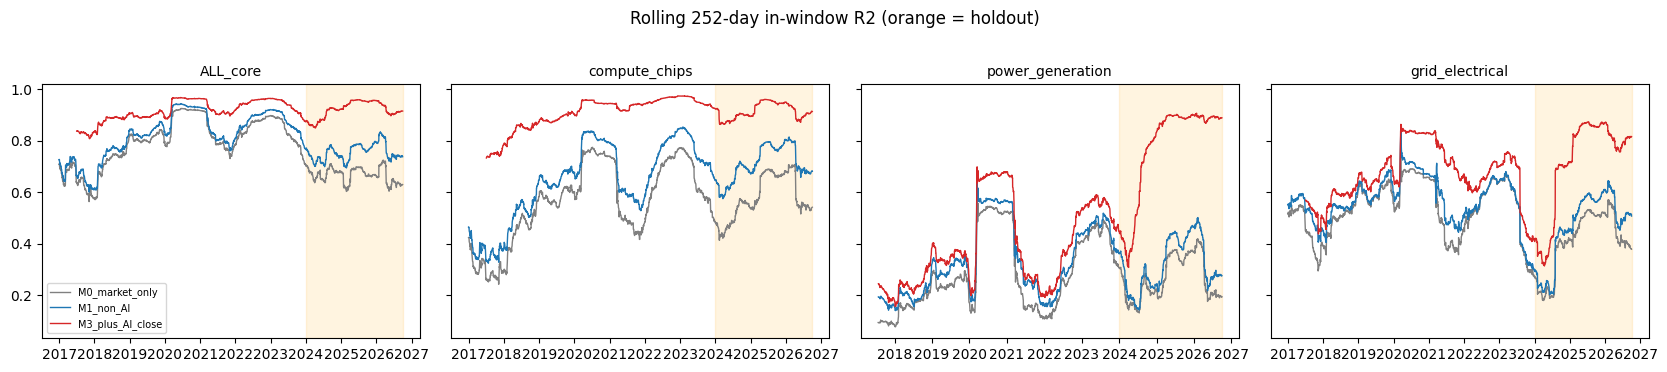

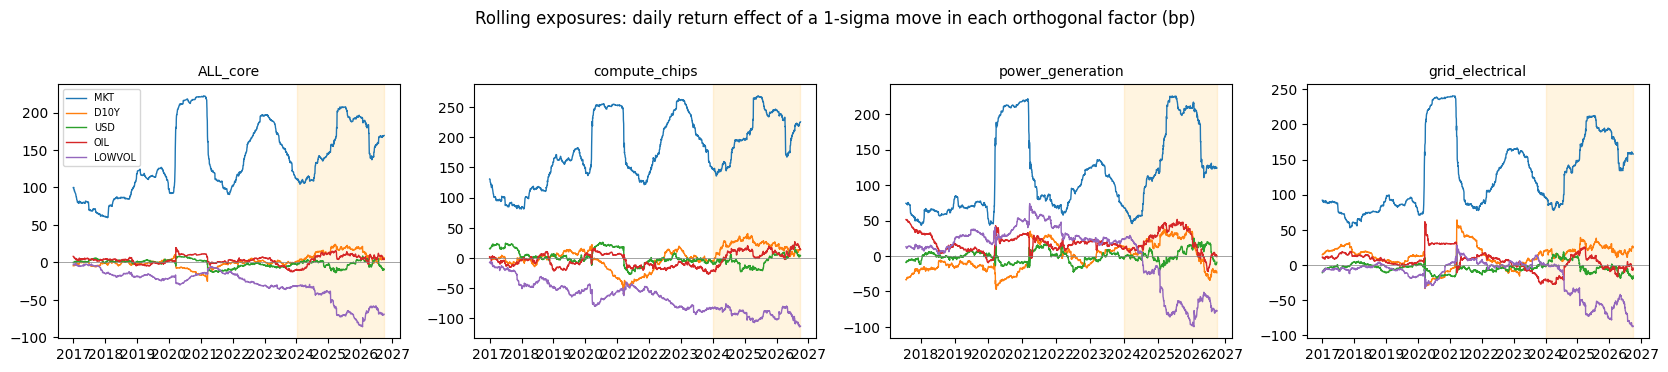

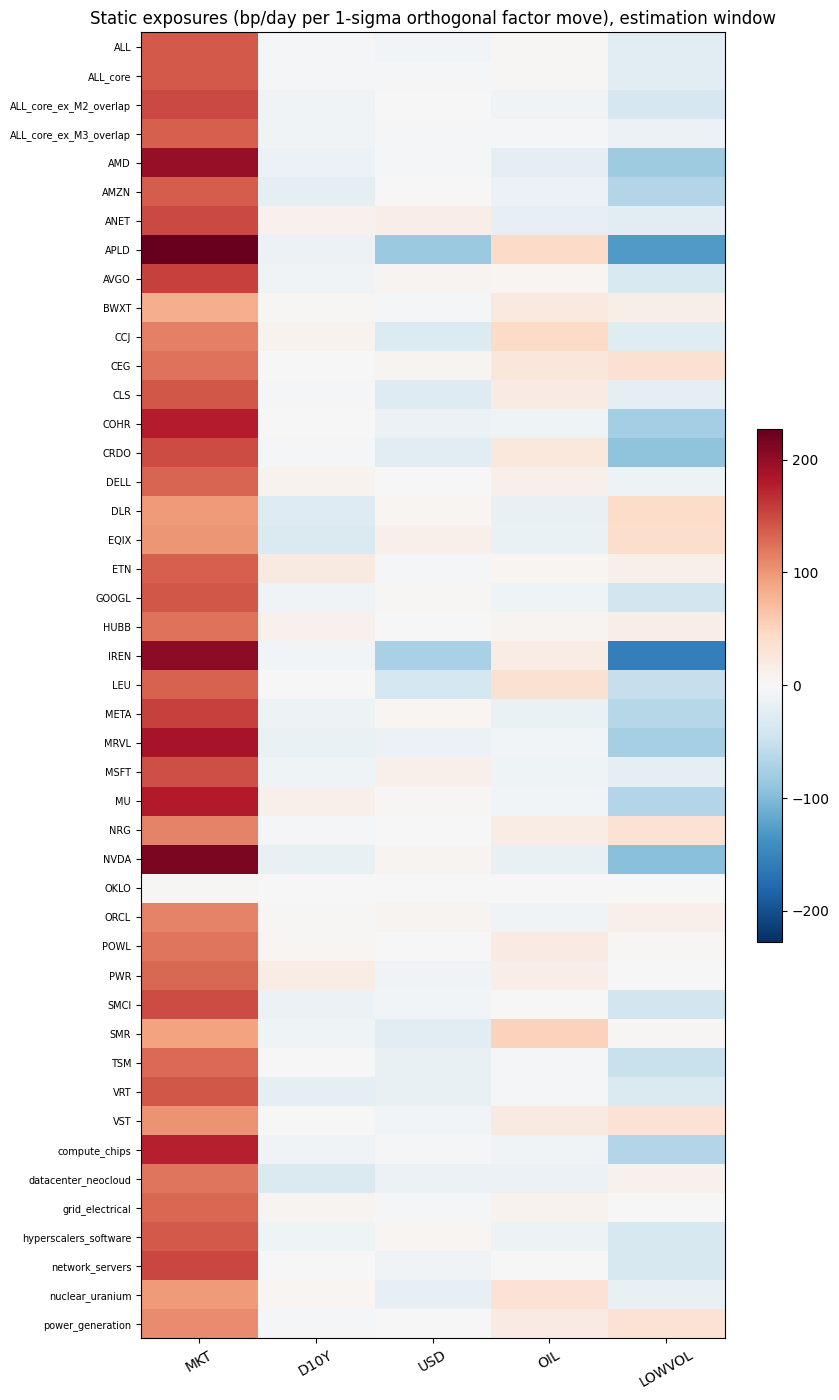

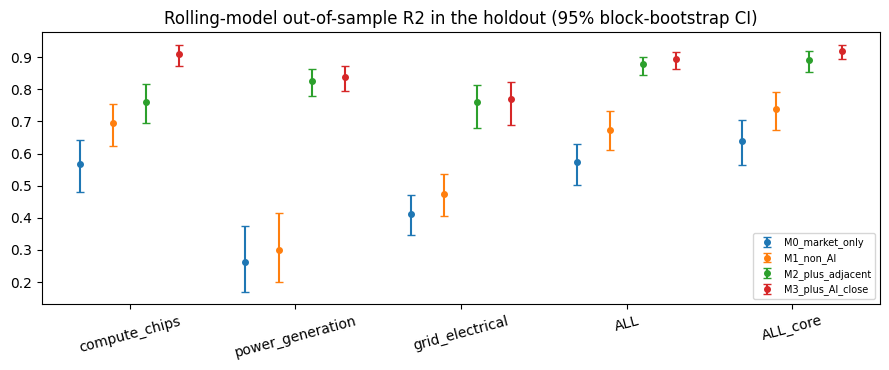

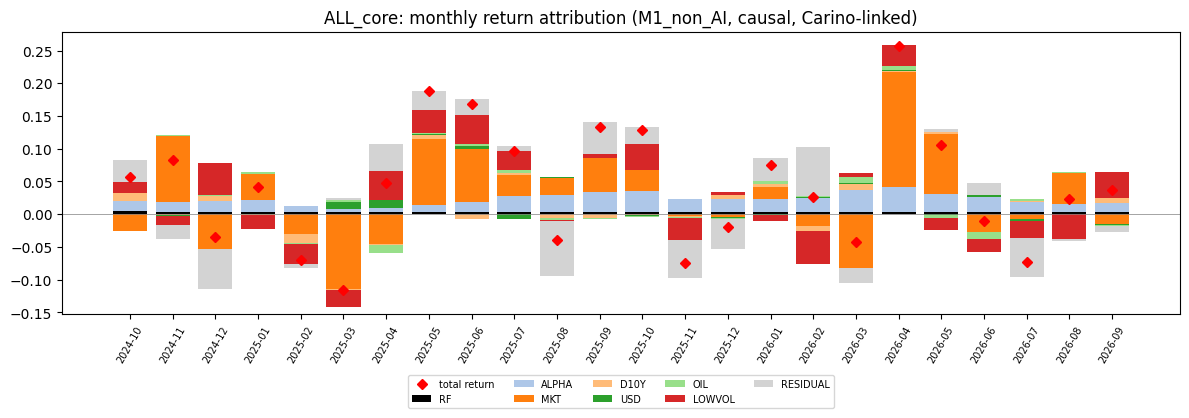

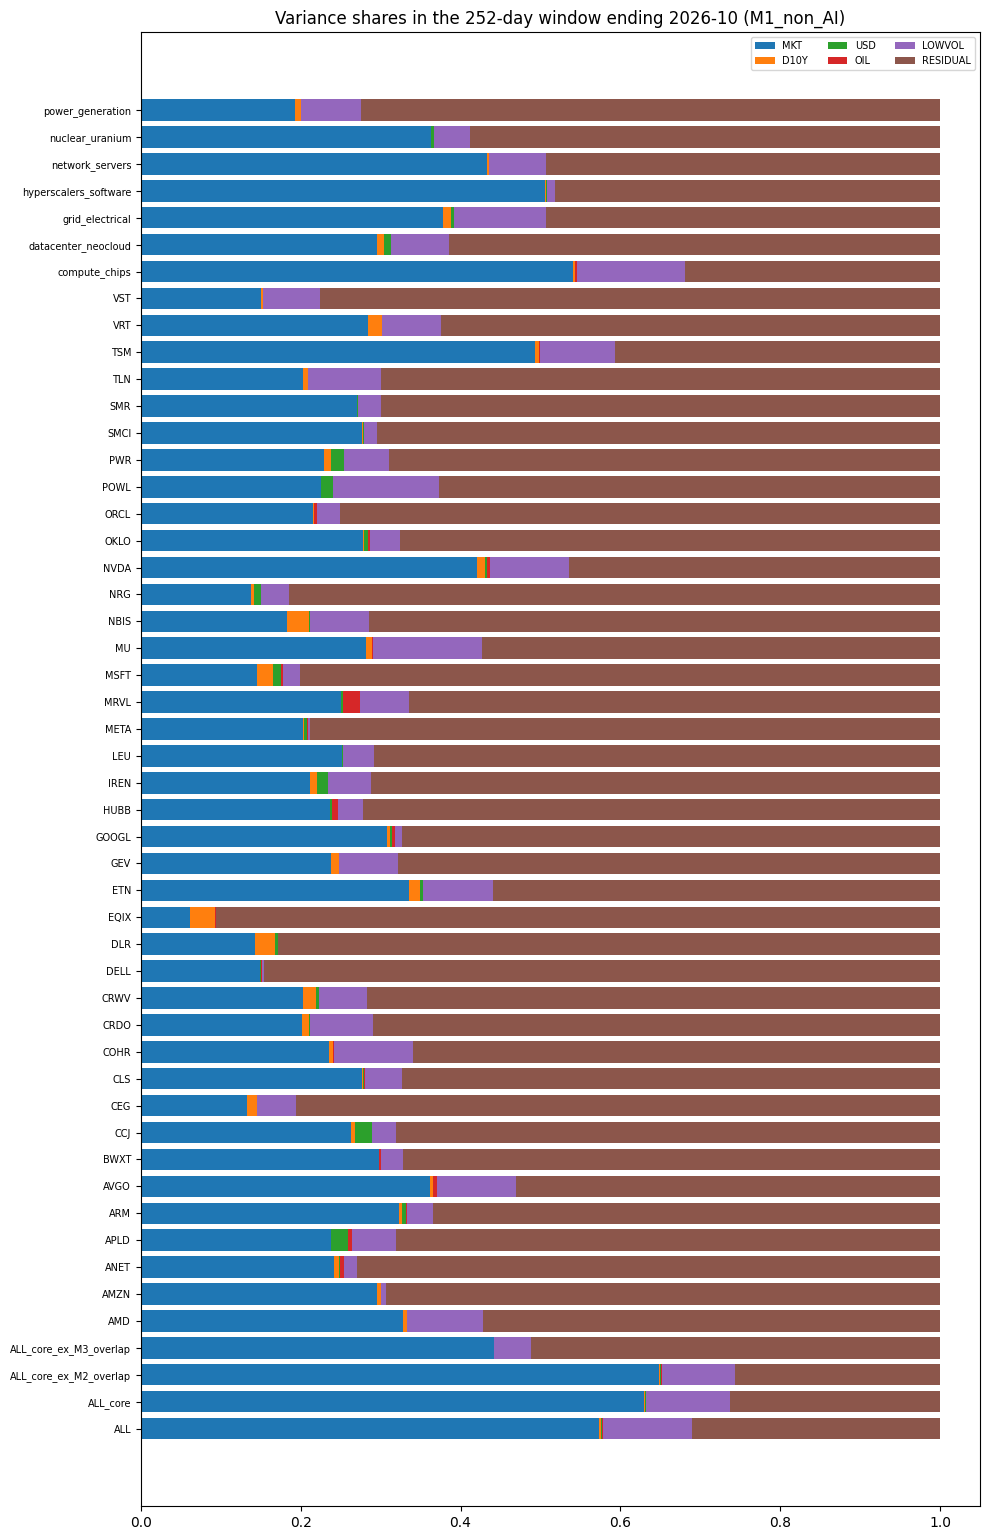

Primary model M1_non_AI: MKT, D10Y, USD, OIL, LOWVOL  (orthogonalised in this order)
39 stocks + 11 baskets | rolling window 252 days, first window ends 2016-12-30
Estimation 2017-01-03 -> 2023-12-29 | holdout 2024-01-02 -> 2026-10-01

=== 1. HOW THE ORTHOGONAL FACTORS ARE BUILT (estimation window): each factor minus its projection on the earlier ones ===
factor   mean    MKT  D10Y    USD    OIL  LOWVOL  z_std
   MKT  0.000  0.000   0.0  0.000  0.000     0.0  0.012
  D10Y  0.081 65.382   0.0  0.000  0.000     0.0  5.452
   USD  0.000 -0.054   0.0  0.000  0.000     0.0  0.004
   OIL  0.000  0.659   0.0 -0.112  0.000     0.0  0.024
LOWVOL -0.000 -0.222  -0.0  0.063 -0.015     0.0  0.004

Raw factor VIF (estimation window):
factor   VIF
   MKT 1.602
  D10Y 1.165
   USD 1.139
   OIL 1.132
LOWVOL 1.560

=== 2. STATIC MODEL FIT: R2 (estimation), adjusted R2, out-of-sample R2 in the holdout (estimation coefficients), re-fitted holdout R2 ===
                target  n_est  r2_est  adj_r2_est  

In [12]:
res = get_results()
make_figures(res)
print_report(res)

In [13]:
import os, sys, json, hashlib, platform, zlib, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

try:
    display
except NameError:                      # plain python (tests); notebooks provide display()
    display = print

# ---- where things live --------------------------------------------------------------------------------
DRIVE_BASE     = "/content/drive/MyDrive/factor_lens"
RAW_VERSION    = "yahoo_2016-01-01_2026-10-01_v1"
CLEAN_VERSION  = "clean_v1"
FACTOR_VERSION = "factors_v1"          # notebook 03 output that holds factors_raw / baskets / basket_members
MODEL_VERSION  = "model_v1"

# ---- windows (same split as notebook 03) --------------------------------------------------------------
EST_START,  EST_END  = "2017-01-03", "2023-12-29"
HOLD_START, HOLD_END = "2024-01-02", "2026-10-01"

FORCE_RECOMPUTE = False
SHOW_FIGURES    = True
CODE_VERSION    = "r5"

# ---- the models: factor ORDER matters for orthogonalisation (earlier factors are removed from later ones) --------
MODELS = {
    "M0_market_only":   ["MKT"],
    "M1_non_AI":        ["MKT", "D10Y", "USD", "OIL", "LOWVOL"],
    "M2_plus_adjacent": ["MKT", "D10Y", "USD", "OIL", "LOWVOL", "POWER", "GRID", "URANIUM"],
    "M3_plus_AI_close": ["MKT", "D10Y", "USD", "OIL", "LOWVOL", "POWER", "GRID", "URANIUM", "SEMI", "SOFT", "ROBO", "MOM"],
}
# Basket layers whose stocks are (largely) HELD by a factor's ETFs (approximate; same map as notebook 03). Used to build the
# overlap-free yardstick baskets: ALL_core without the layers held by the model's own factors.
OVERLAP = {
    "SEMI": ["compute_chips"], "ROBO": ["compute_chips"], "SOFT": ["hyperscalers_software"], "CLOUD": ["hyperscalers_software"],
    "INFRA": ["datacenter_neocloud"], "UTIL": ["power_generation"], "POWER": ["power_generation"],
    "GRID": ["grid_electrical"], "CAPEX": ["grid_electrical"], "URANIUM": ["nuclear_uranium"],
}
PRIMARY_MODEL = "M2_plus_adjacent"
BASELINE_MODEL = "M0_market_only"
REPORT_MONTHS = None        # e.g. ["2026-07", "2026-08", "2026-09"]; None = the last 3 complete months
AI_CLOSE_TEST_STOCKS = ['NVDA', 'AVGO', 'MSFT', 'AMZN', 'GOOGL', 'META', 'ORCL']
NON_AI_CONTROL_STOCKS = ['KO', 'PG', 'WMT', 'MCD', 'JNJ', 'JPM', 'XOM', 'CAT']

CFG = dict(
    window=252,               # sliding-window length (trading days)
    min_rows=200,             # minimum complete factor rows in a window
    min_obs_target=200,       # minimum valid target observations in a window
    nw_lags=5,                # Newey-West lags
    lb_lags=10, arch_lags=5,  # residual diagnostics
    boot_B=500, boot_block=20, boot_seed=2026, ci_level=0.95,
    shift_z=2.0,              # |z| above this flags a parameter shift (estimation -> holdout)
    min_effect=0.01,          # an R2 increment needs |delta| >= this AND a CI excluding 0 to be starred
    top_n=8,
    min_total_vol=0.15,       # annualised volatility below this over the estimation window => flagged as a suspect (shell / non-trading) history
)

Fitting the models ...
Saved to /content/drive/MyDrive/factor_lens/models/model_v1__factors_v1__clean_v1__yahoo_2016-01-01_2026-10-01_v1


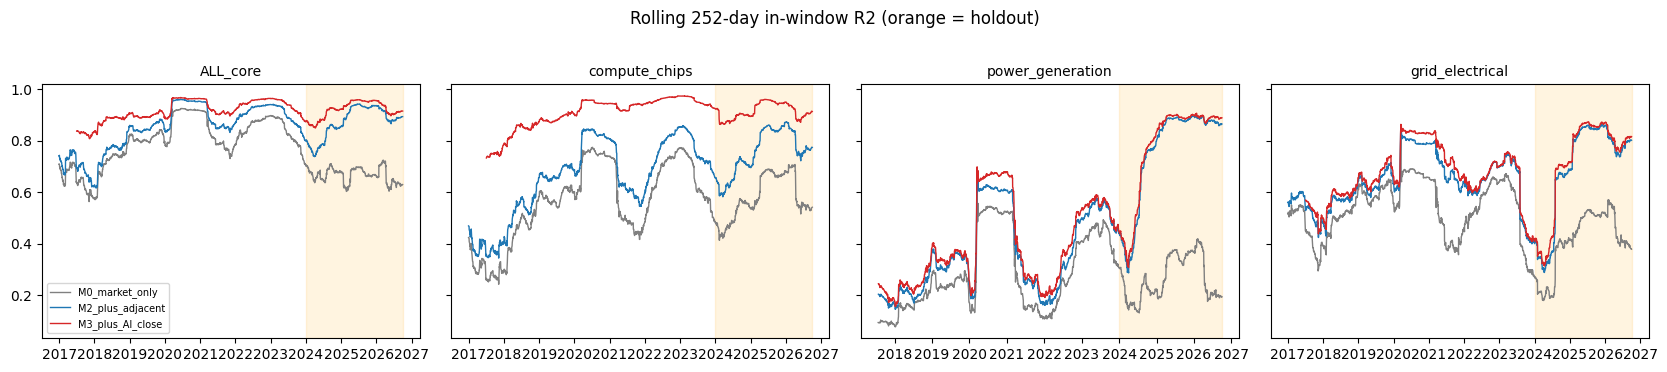

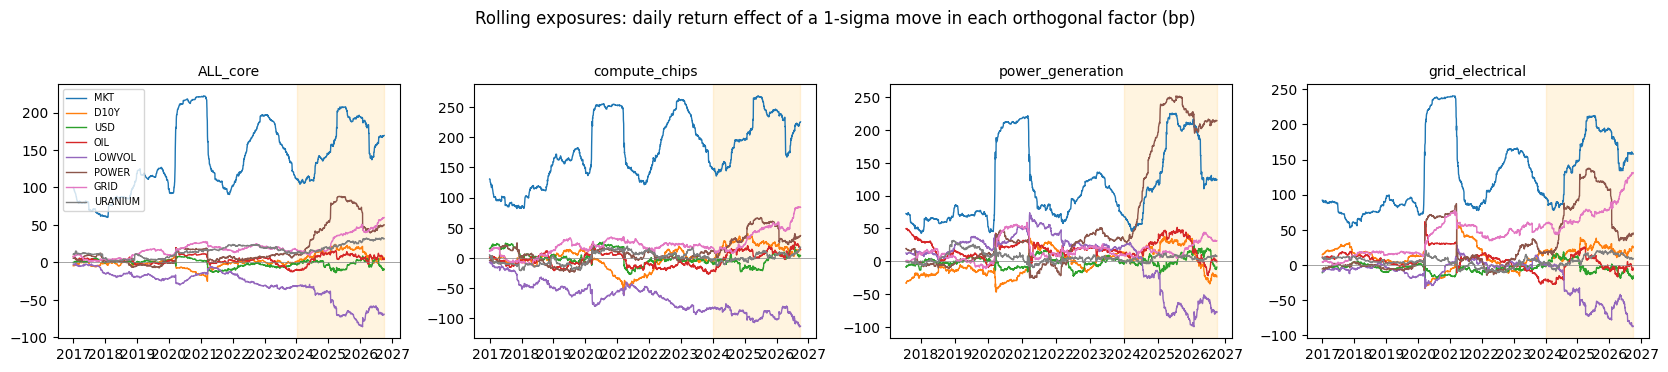

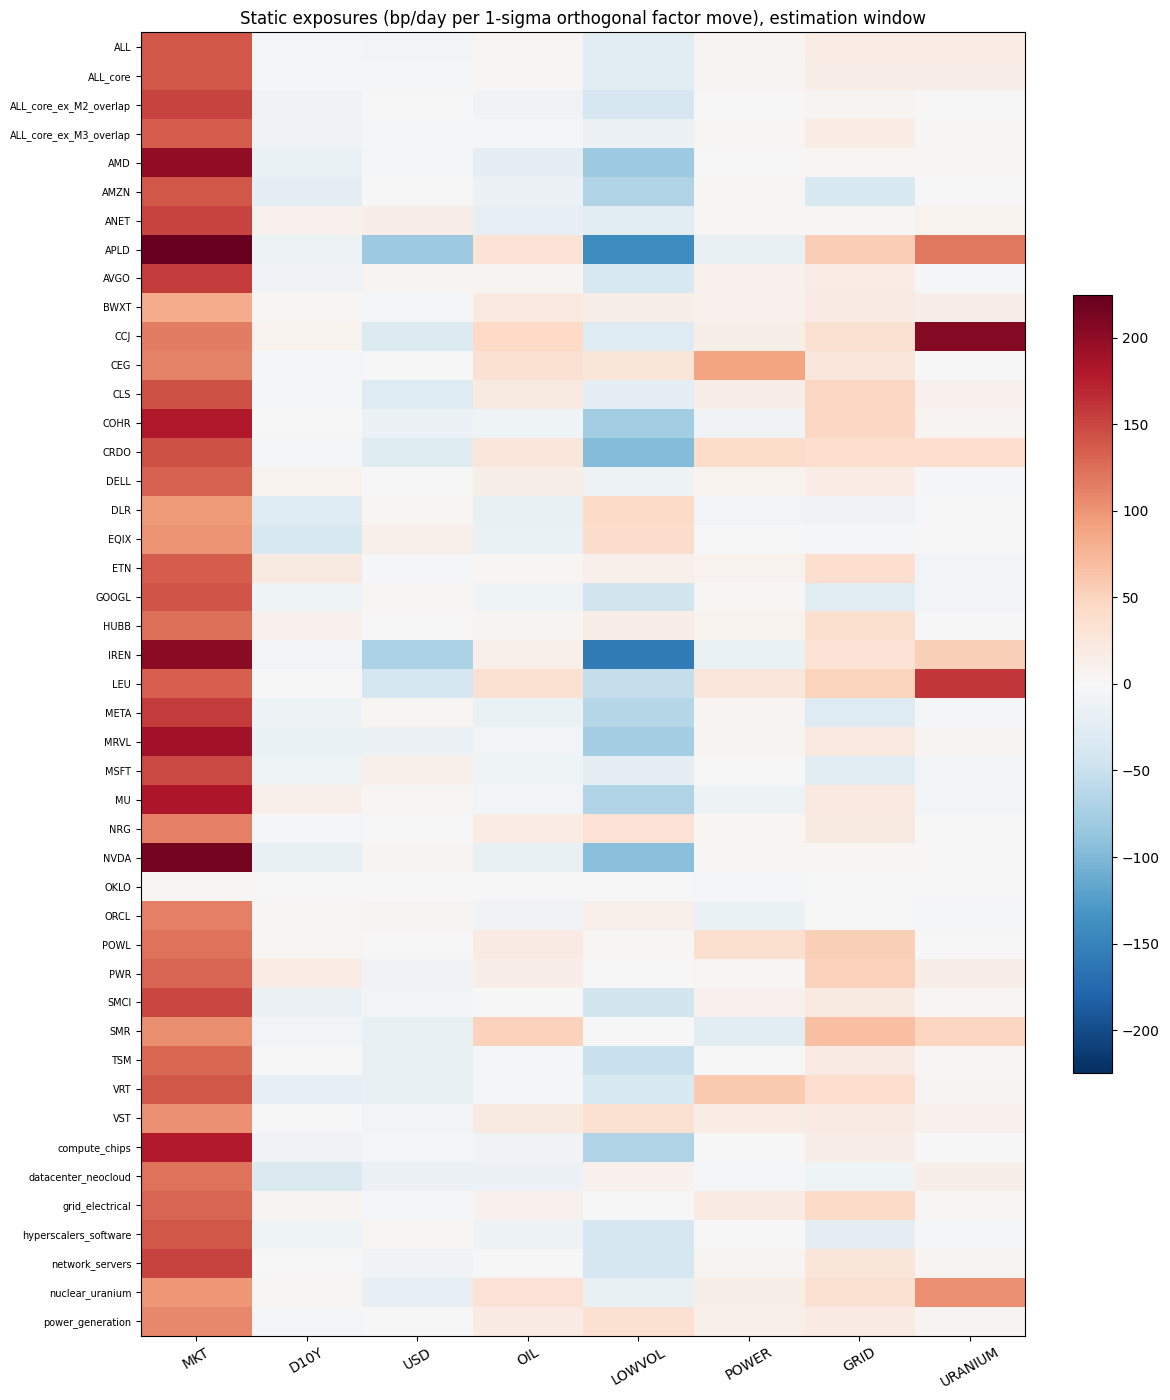

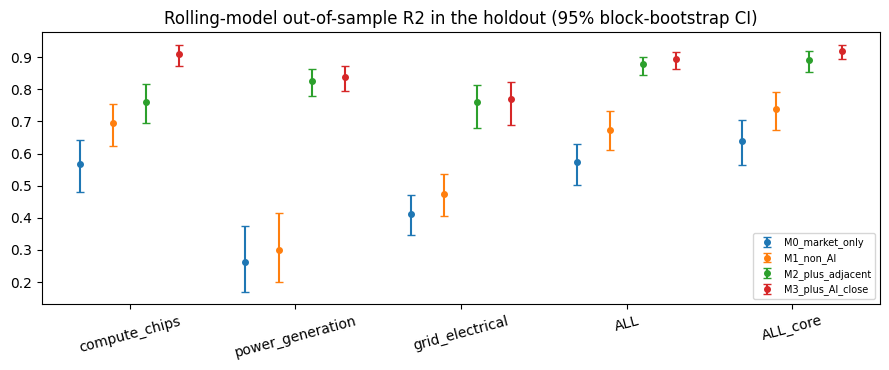

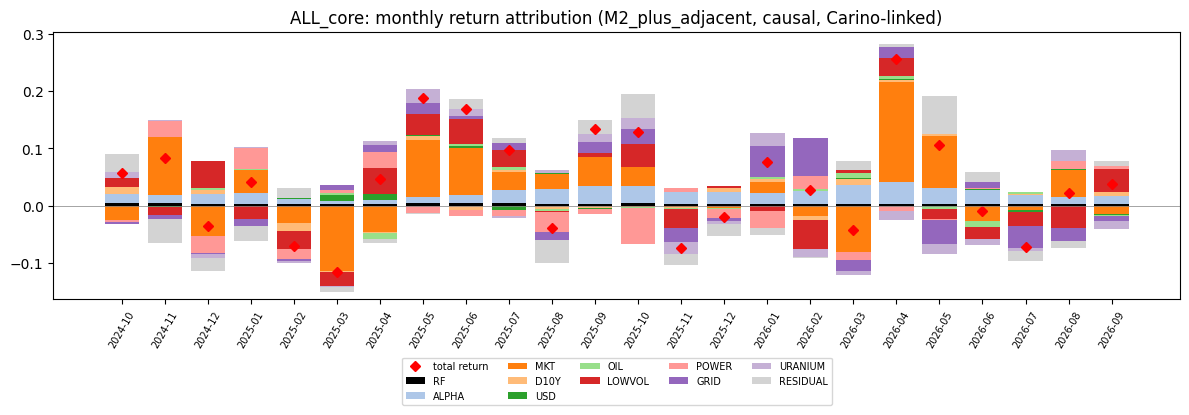

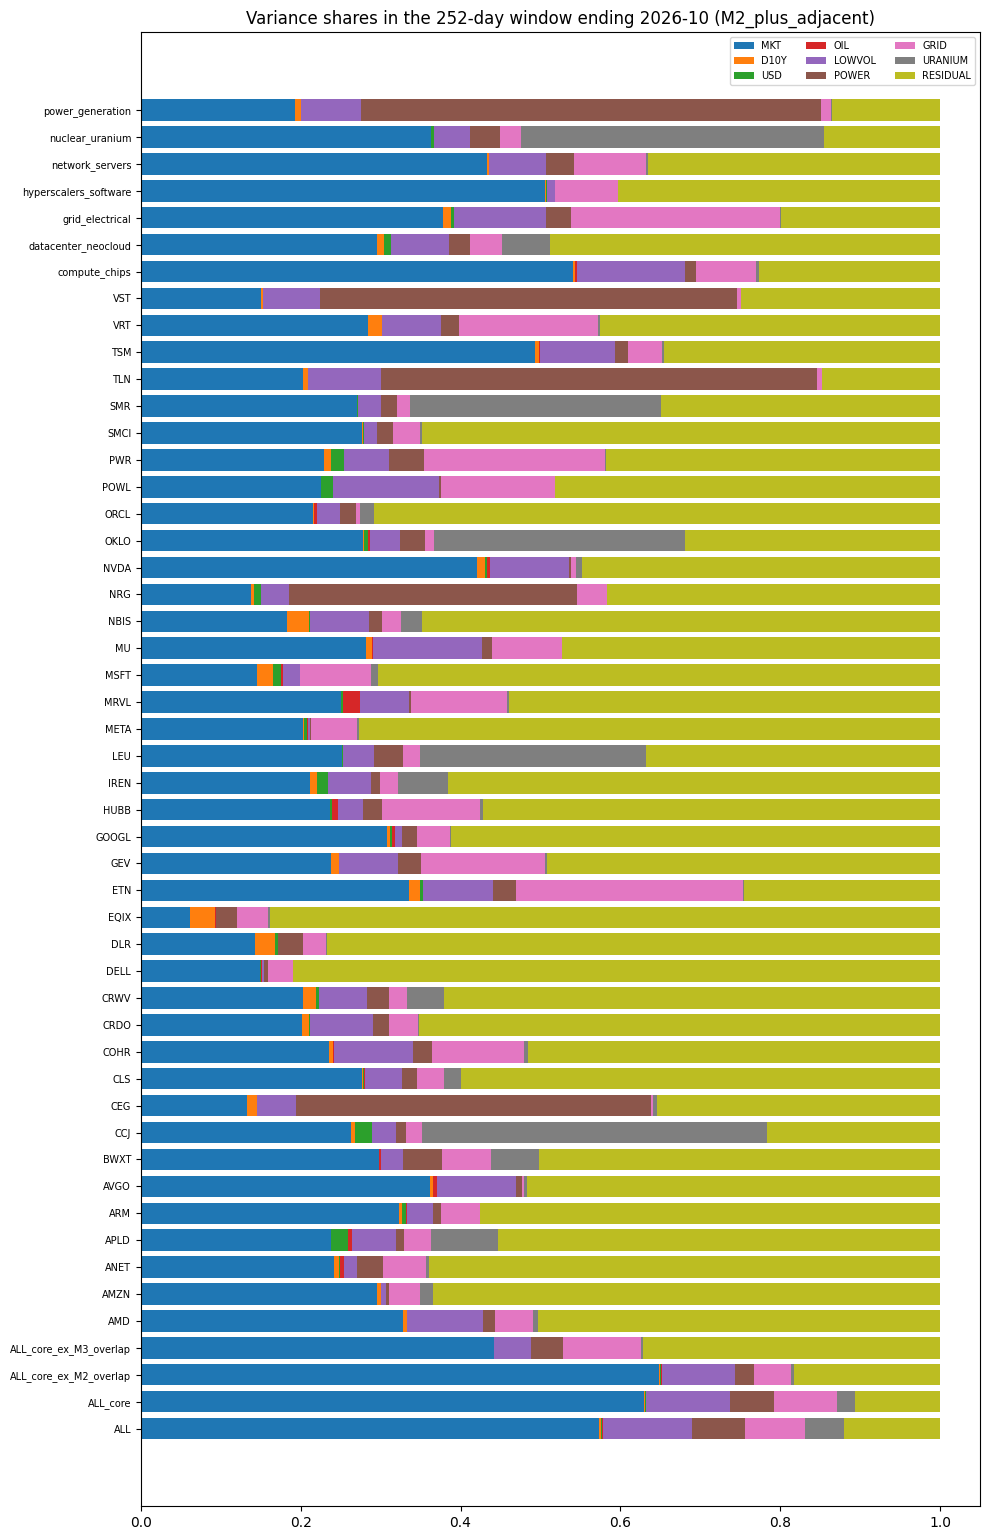

Primary model M2_plus_adjacent: MKT, D10Y, USD, OIL, LOWVOL, POWER, GRID, URANIUM  (orthogonalised in this order)
39 stocks + 11 baskets | rolling window 252 days, first window ends 2016-12-30
Estimation 2017-01-03 -> 2023-12-29 | holdout 2024-01-02 -> 2026-10-01

=== 1. HOW THE ORTHOGONAL FACTORS ARE BUILT (estimation window): each factor minus its projection on the earlier ones ===
 factor   mean    MKT  D10Y    USD    OIL  LOWVOL  POWER  GRID  URANIUM  z_std
    MKT  0.000  0.000   0.0  0.000  0.000   0.000  0.000 0.000      0.0  0.012
   D10Y  0.071 64.633   0.0  0.000  0.000   0.000  0.000 0.000      0.0  5.460
    USD  0.000 -0.053   0.0  0.000  0.000   0.000  0.000 0.000      0.0  0.004
    OIL  0.000  0.659   0.0 -0.111  0.000   0.000  0.000 0.000      0.0  0.024
 LOWVOL -0.000 -0.222  -0.0  0.065 -0.015   0.000  0.000 0.000      0.0  0.004
  POWER  0.000 -0.049   0.0 -0.076  0.027  -0.268  0.000 0.000      0.0  0.005
   GRID  0.000  0.042  -0.0 -0.413  0.018  -0.231  0.179 0.0

In [14]:
res = get_results()
make_figures(res)
print_report(res)

In [15]:
import os, sys, json, hashlib, platform, zlib, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

try:
    display
except NameError:                      # plain python (tests); notebooks provide display()
    display = print

# ---- where things live --------------------------------------------------------------------------------
DRIVE_BASE     = "/content/drive/MyDrive/factor_lens"
RAW_VERSION    = "yahoo_2016-01-01_2026-10-01_v1"
CLEAN_VERSION  = "clean_v1"
FACTOR_VERSION = "factors_v1"          # notebook 03 output that holds factors_raw / baskets / basket_members
MODEL_VERSION  = "model_v1"

# ---- windows (same split as notebook 03) --------------------------------------------------------------
EST_START,  EST_END  = "2017-01-03", "2023-12-29"
HOLD_START, HOLD_END = "2024-01-02", "2026-10-01"

FORCE_RECOMPUTE = False
SHOW_FIGURES    = True
CODE_VERSION    = "r5"

# ---- the models: factor ORDER matters for orthogonalisation (earlier factors are removed from later ones) --------
MODELS = {
    "M0_market_only":   ["MKT"],
    "M1_non_AI":        ["MKT", "D10Y", "USD", "OIL", "LOWVOL"],
    "M2_plus_adjacent": ["MKT", "D10Y", "USD", "OIL", "LOWVOL", "POWER", "GRID", "URANIUM"],
    "M3_plus_AI_close": ["MKT", "D10Y", "USD", "OIL", "LOWVOL", "POWER", "GRID", "URANIUM", "SEMI", "SOFT", "ROBO", "MOM"],
}
# Basket layers whose stocks are (largely) HELD by a factor's ETFs (approximate; same map as notebook 03). Used to build the
# overlap-free yardstick baskets: ALL_core without the layers held by the model's own factors.
OVERLAP = {
    "SEMI": ["compute_chips"], "ROBO": ["compute_chips"], "SOFT": ["hyperscalers_software"], "CLOUD": ["hyperscalers_software"],
    "INFRA": ["datacenter_neocloud"], "UTIL": ["power_generation"], "POWER": ["power_generation"],
    "GRID": ["grid_electrical"], "CAPEX": ["grid_electrical"], "URANIUM": ["nuclear_uranium"],
}
PRIMARY_MODEL = "M3_plus_AI_close"
BASELINE_MODEL = "M0_market_only"
REPORT_MONTHS = None        # e.g. ["2026-07", "2026-08", "2026-09"]; None = the last 3 complete months
AI_CLOSE_TEST_STOCKS = ['NVDA', 'AVGO', 'MSFT', 'AMZN', 'GOOGL', 'META', 'ORCL']
NON_AI_CONTROL_STOCKS = ['KO', 'PG', 'WMT', 'MCD', 'JNJ', 'JPM', 'XOM', 'CAT']

CFG = dict(
    window=252,               # sliding-window length (trading days)
    min_rows=200,             # minimum complete factor rows in a window
    min_obs_target=200,       # minimum valid target observations in a window
    nw_lags=5,                # Newey-West lags
    lb_lags=10, arch_lags=5,  # residual diagnostics
    boot_B=500, boot_block=20, boot_seed=2026, ci_level=0.95,
    shift_z=2.0,              # |z| above this flags a parameter shift (estimation -> holdout)
    min_effect=0.01,          # an R2 increment needs |delta| >= this AND a CI excluding 0 to be starred
    top_n=8,
    min_total_vol=0.15,       # annualised volatility below this over the estimation window => flagged as a suspect (shell / non-trading) history
)

Fitting the models ...
Saved to /content/drive/MyDrive/factor_lens/models/model_v1__factors_v1__clean_v1__yahoo_2016-01-01_2026-10-01_v1


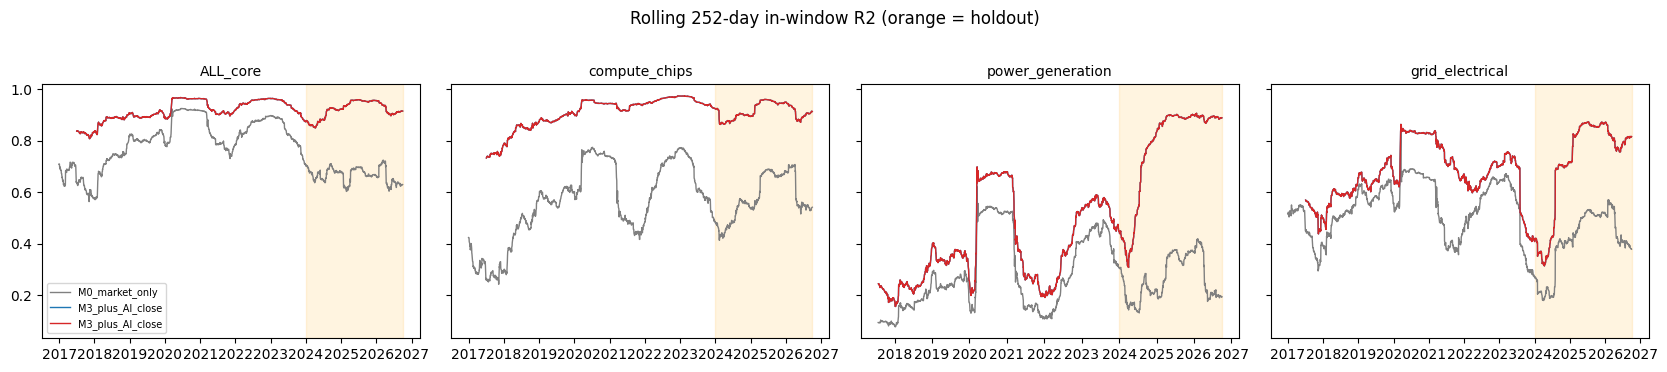

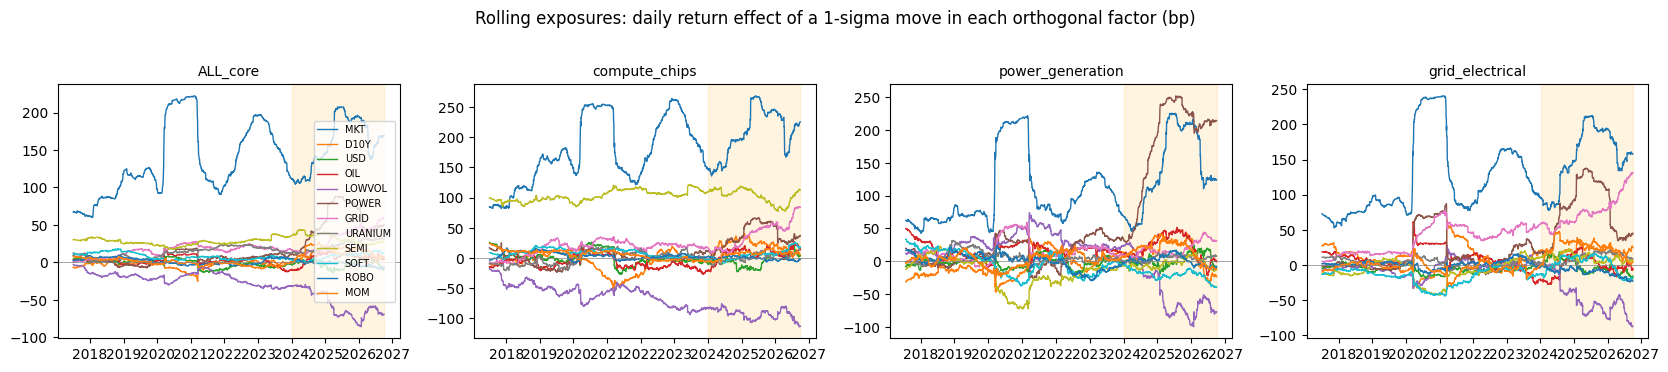

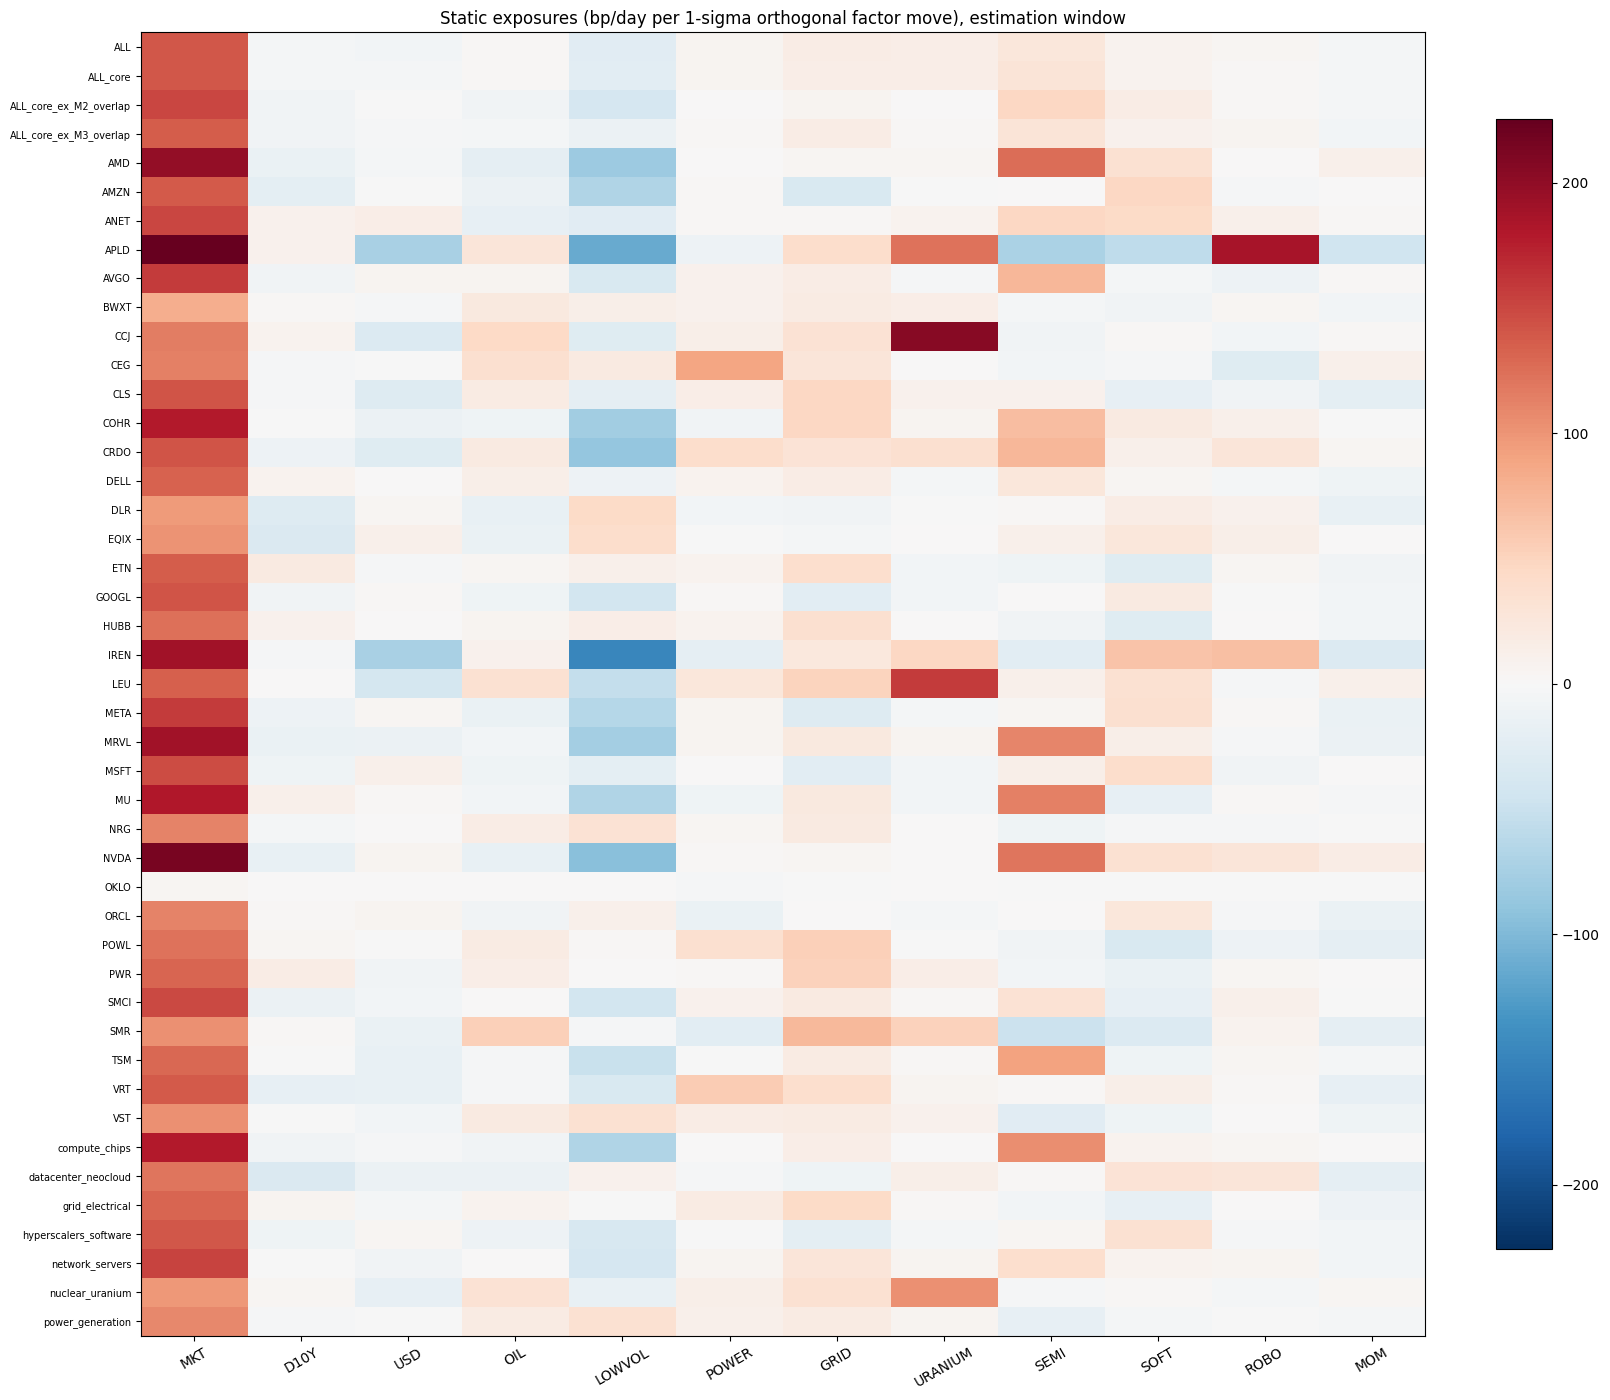

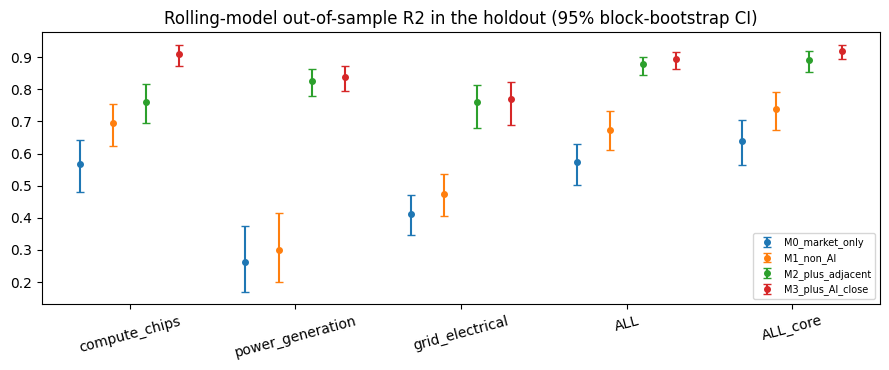

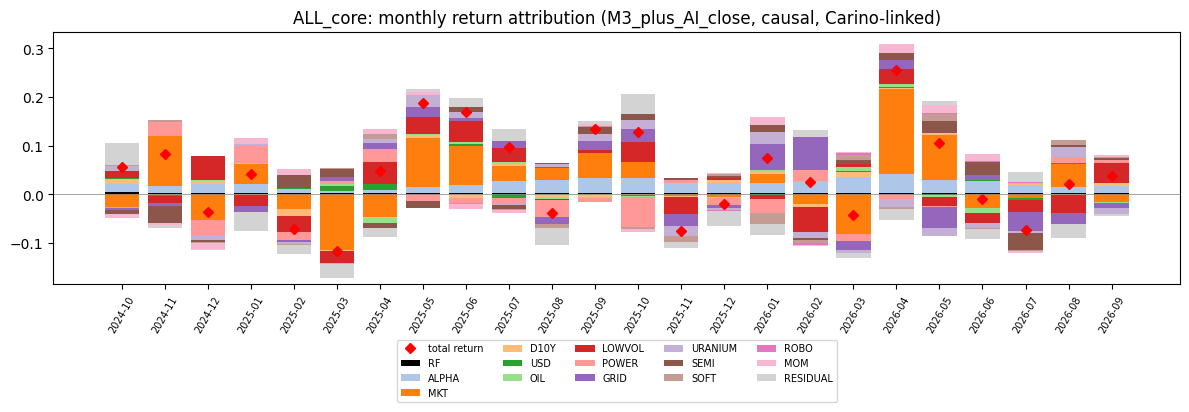

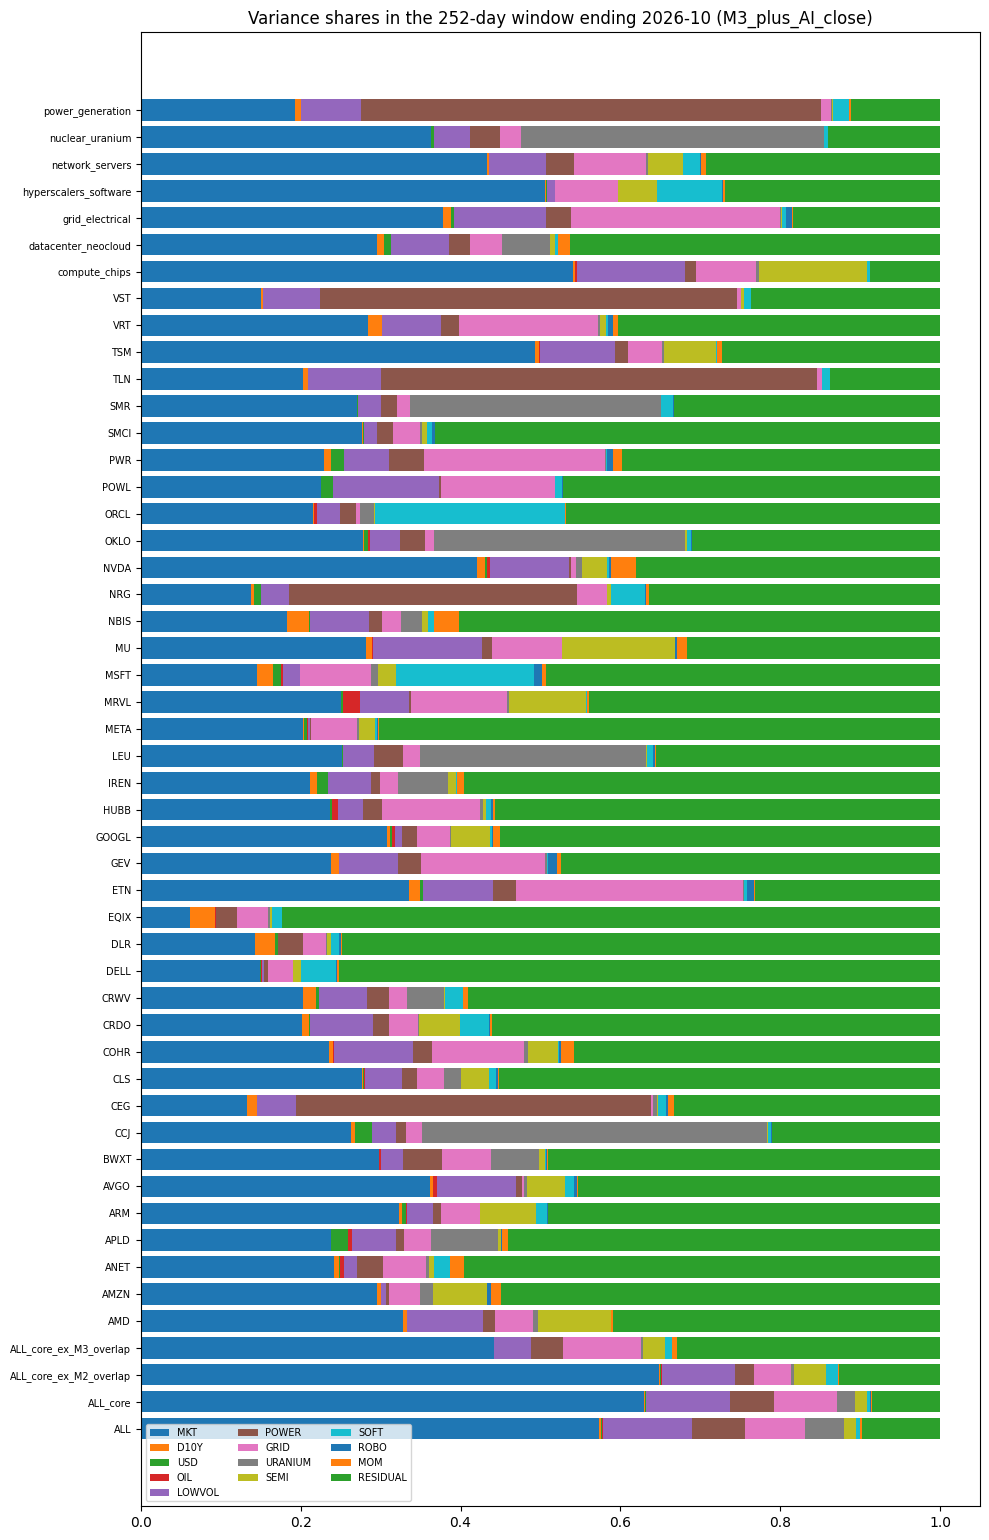

Primary model M3_plus_AI_close: MKT, D10Y, USD, OIL, LOWVOL, POWER, GRID, URANIUM, SEMI, SOFT, ROBO, MOM  (orthogonalised in this order)
39 stocks + 11 baskets | rolling window 252 days, first window ends 2017-07-03
Estimation 2017-01-03 -> 2023-12-29 | holdout 2024-01-02 -> 2026-10-01

=== 1. HOW THE ORTHOGONAL FACTORS ARE BUILT (estimation window): each factor minus its projection on the earlier ones ===
 factor   mean    MKT  D10Y    USD    OIL  LOWVOL  POWER   GRID  URANIUM  SEMI  SOFT   ROBO  MOM  z_std
    MKT  0.000  0.000   0.0  0.000  0.000   0.000  0.000  0.000    0.000 0.000 0.000  0.000  0.0  0.012
   D10Y  0.071 64.633   0.0  0.000  0.000   0.000  0.000  0.000    0.000 0.000 0.000  0.000  0.0  5.460
    USD  0.000 -0.053   0.0  0.000  0.000   0.000  0.000  0.000    0.000 0.000 0.000  0.000  0.0  0.004
    OIL  0.000  0.659   0.0 -0.111  0.000   0.000  0.000  0.000    0.000 0.000 0.000  0.000  0.0  0.024
 LOWVOL -0.000 -0.222  -0.0  0.065 -0.015   0.000  0.000  0.000    0.0

In [16]:
res = get_results()
make_figures(res)
print_report(res)

## 12. Visual model check: realised versus predicted returns

These charts use the causal rolling model. For each day, the model parameters come from the rolling window ending on the previous trading day. The predicted excess return is the sum of alpha and factor contributions; the gap to the realised excess return is the residual.


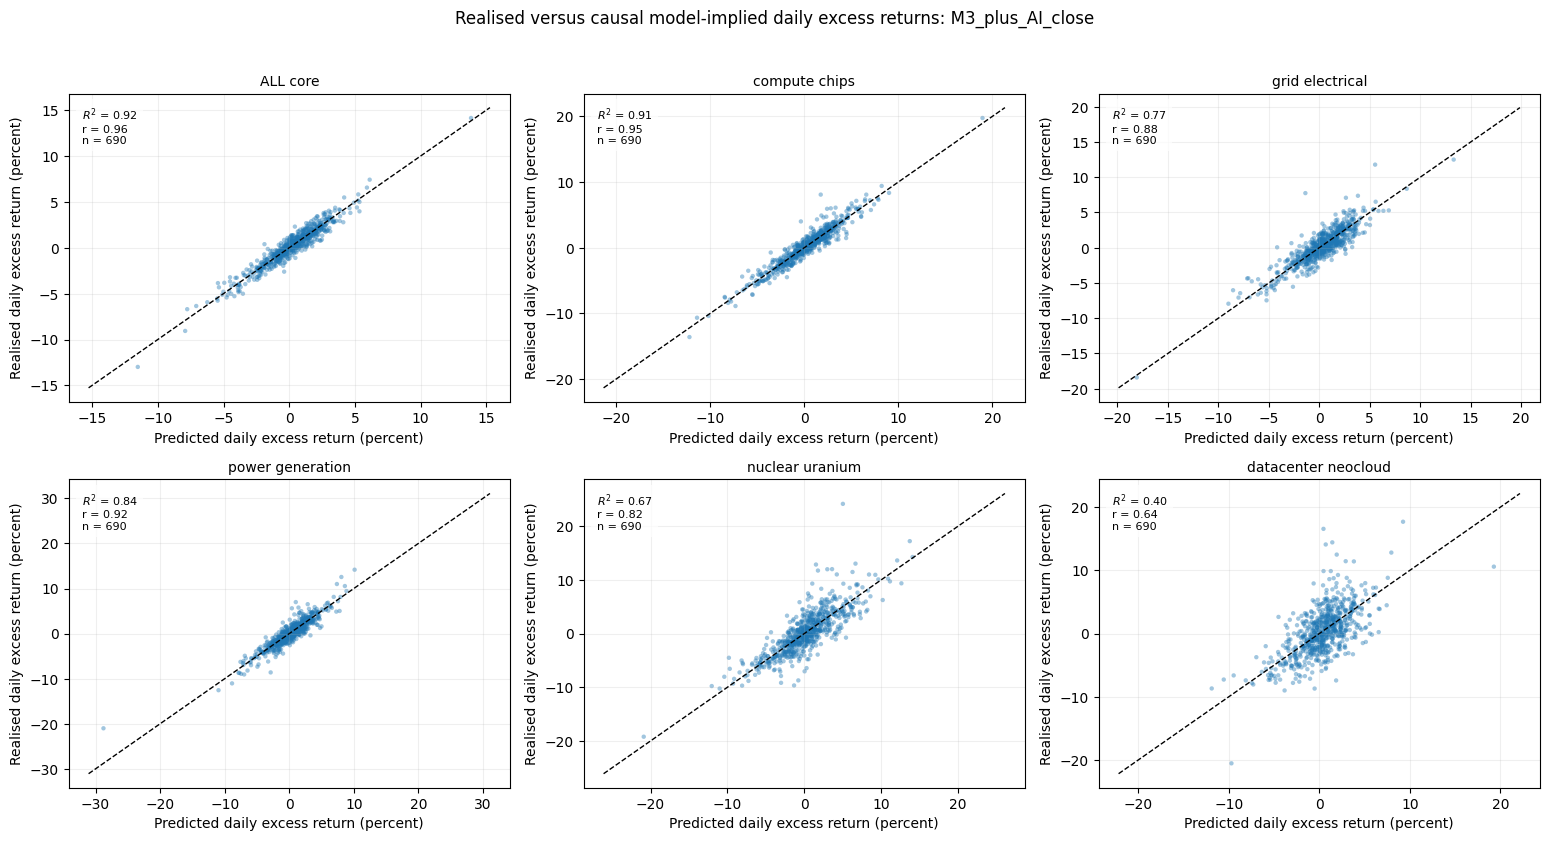

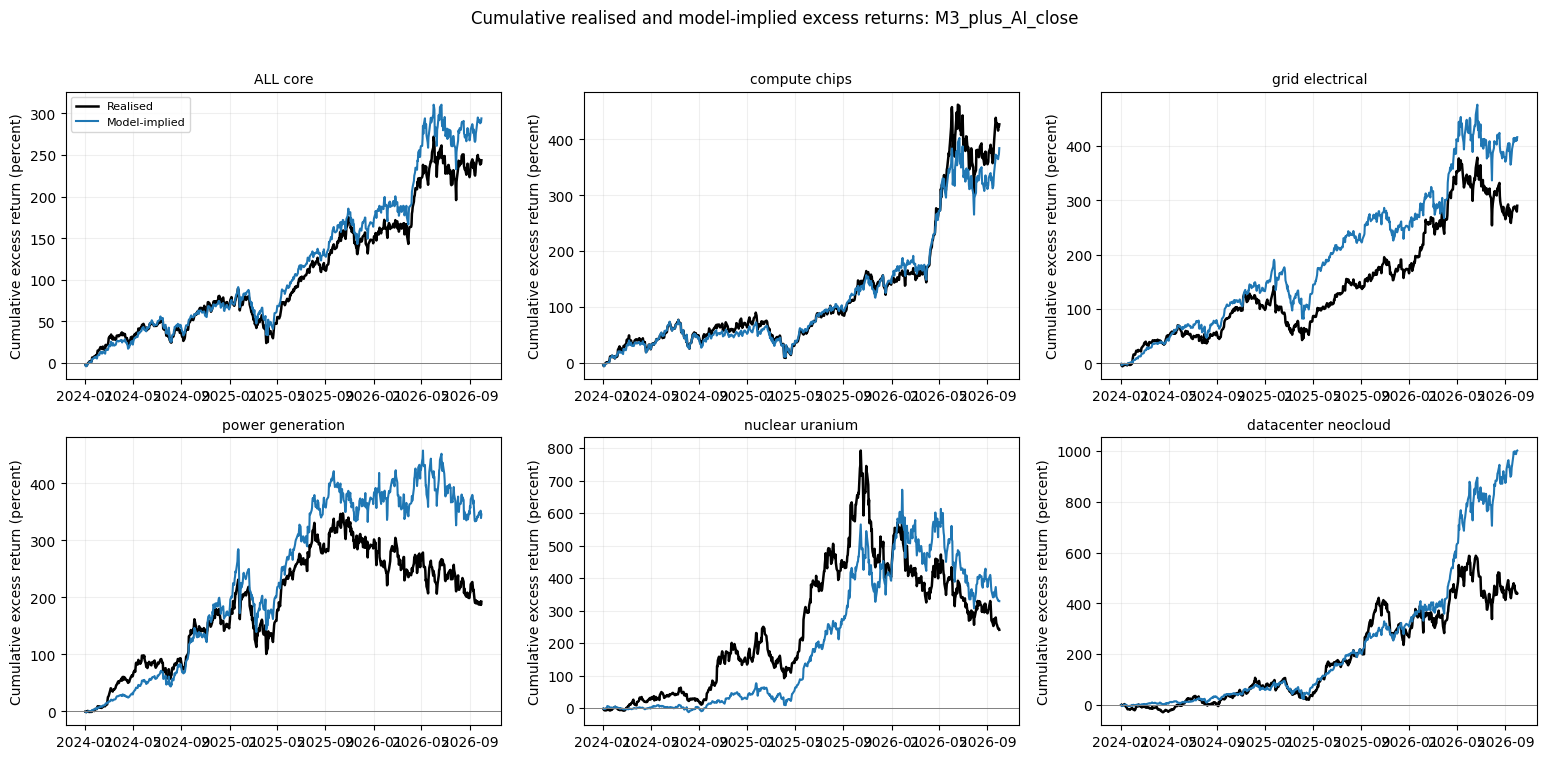

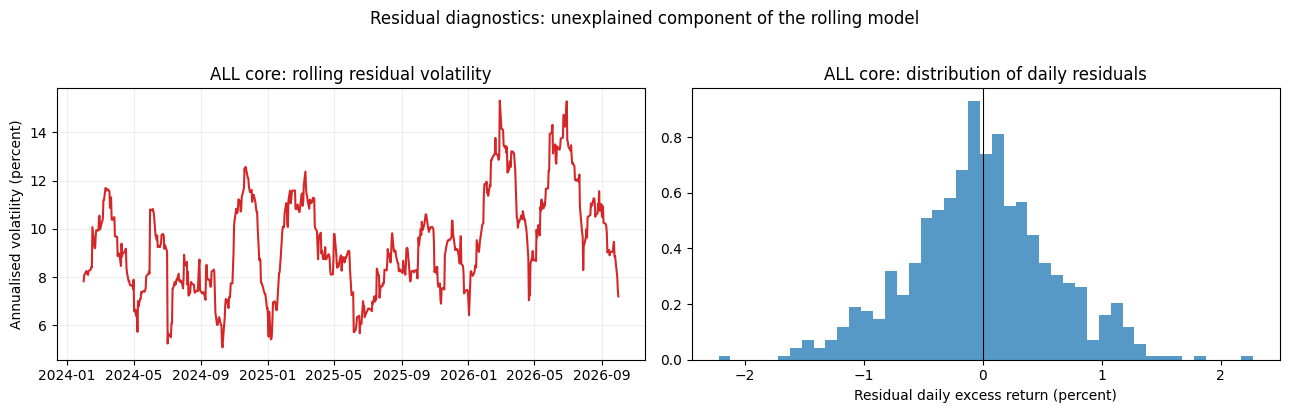

In [17]:
# Run after: res = get_results(). Uses attr_daily_baskets, so it also works after a cache hit.

def model_daily_frame(results, target, start=HOLD_START, end=HOLD_END):
    """Return realised and causal model-implied daily excess returns for one basket target."""
    # attr_daily_all is created by the current version and includes baskets and stocks.
    if 'attr_daily_all' not in results:
        raise KeyError('Run the notebook from the top once to create attr_daily_all for stock-level plots.')
    d = results['attr_daily_all'].copy()
    d['date'] = pd.to_datetime(d['date'])
    d = d[(d['target'] == target) & (d['date'] >= pd.Timestamp(start)) & (d['date'] <= pd.Timestamp(end))].copy()
    factors = MODELS[PRIMARY_MODEL]
    d['predicted_excess'] = d['ALPHA'] + d[factors].sum(axis=1)
    d['residual'] = d['excess_return'] - d['predicted_excess']
    return d.sort_values('date').set_index('date')

def plot_prediction_diagnostics(results, targets=None, start=HOLD_START, end=HOLD_END):
    """Scatter, cumulative-excess-return, and residual diagnostics for selected basket layers."""
    if targets is None:
        preferred = ['ALL_core', 'compute_chips', 'grid_electrical', 'power_generation', 'nuclear_uranium', 'datacenter_neocloud']
        available = set(results['attr_daily_baskets']['target'])
        targets = [t for t in preferred if t in available]

    n = len(targets)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(5.2 * cols, 4.1 * rows), squeeze=False)
    for ax, target in zip(axs.ravel(), targets):
        d = model_daily_frame(results, target, start, end).dropna(subset=['excess_return', 'predicted_excess'])
        lim = max(d['excess_return'].abs().max(), d['predicted_excess'].abs().max()) * 1.08
        ax.scatter(d['predicted_excess'] * 100, d['excess_return'] * 100, s=10, alpha=0.42, color='tab:blue', edgecolor='none')
        ax.plot([-lim * 100, lim * 100], [-lim * 100, lim * 100], color='black', lw=1, ls='--')
        corr = d['predicted_excess'].corr(d['excess_return'])
        r2 = 1.0 - (d['residual'] ** 2).sum() / ((d['excess_return'] - d['excess_return'].mean()) ** 2).sum()
        ax.set_title(target.replace('_', ' '), fontsize=10)
        ax.text(0.03, 0.96, f'$R^2$ = {r2:.2f}\nr = {corr:.2f}\nn = {len(d)}', transform=ax.transAxes, va='top', fontsize=8, bbox=dict(facecolor='white', alpha=0.75, edgecolor='none'))
        ax.set_xlabel('Predicted daily excess return (percent)')
        ax.set_ylabel('Realised daily excess return (percent)')
        ax.grid(alpha=0.2)
    for ax in axs.ravel()[n:]: ax.axis('off')
    fig.suptitle(f'Realised versus causal model-implied daily excess returns: {PRIMARY_MODEL}', y=1.02)
    fig.tight_layout(); plt.show()

    fig, axs = plt.subplots(rows, cols, figsize=(5.2 * cols, 3.7 * rows), squeeze=False)
    for ax, target in zip(axs.ravel(), targets):
        d = model_daily_frame(results, target, start, end).dropna(subset=['excess_return', 'predicted_excess'])
        realised = (1.0 + d['excess_return']).cumprod() - 1.0
        predicted = (1.0 + d['predicted_excess']).cumprod() - 1.0
        ax.plot(d.index, realised * 100, color='black', lw=1.8, label='Realised')
        ax.plot(d.index, predicted * 100, color='tab:blue', lw=1.5, label='Model-implied')
        ax.axhline(0, color='grey', lw=0.7)
        ax.set_title(target.replace('_', ' '), fontsize=10)
        ax.set_ylabel('Cumulative excess return (percent)')
        ax.grid(alpha=0.2)
    axs[0, 0].legend(fontsize=8)
    for ax in axs.ravel()[n:]: ax.axis('off')
    fig.suptitle(f'Cumulative realised and model-implied excess returns: {PRIMARY_MODEL}', y=1.02)
    fig.tight_layout(); plt.show()

    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    d = model_daily_frame(results, 'ALL_core', start, end).dropna(subset=['residual'])
    axs[0].plot(d.index, d['residual'].rolling(21).std() * np.sqrt(252) * 100, color='tab:red')
    axs[0].set_title('ALL core: rolling residual volatility')
    axs[0].set_ylabel('Annualised volatility (percent)')
    axs[0].grid(alpha=0.2)
    axs[1].hist(d['residual'] * 100, bins=45, color='tab:blue', alpha=0.75, density=True)
    axs[1].axvline(0, color='black', lw=0.8)
    axs[1].set_title('ALL core: distribution of daily residuals')
    axs[1].set_xlabel('Residual daily excess return (percent)')
    fig.suptitle('Residual diagnostics: unexplained component of the rolling model', y=1.02)
    fig.tight_layout(); plt.show()

plot_prediction_diagnostics(res)


### Individual-stock visual check

Use the next cell for any eligible stock, for example `plot_stock_prediction_diagnostics(res, 'NVDA')`.


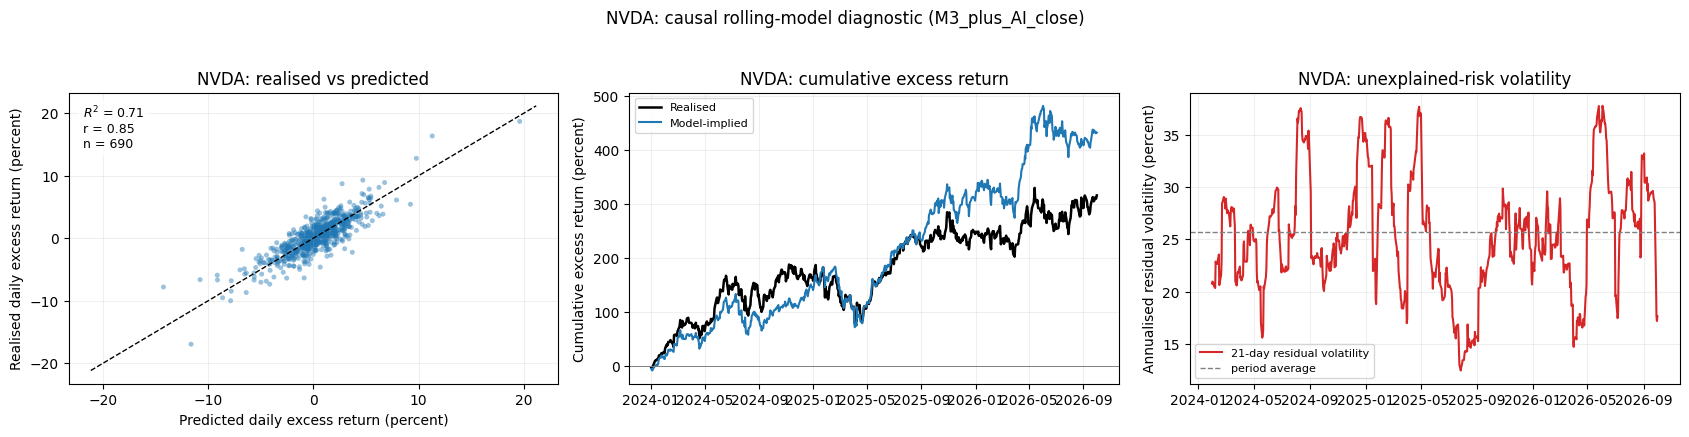

In [18]:
def plot_stock_prediction_diagnostics(results, ticker, start=HOLD_START, end=HOLD_END):
    """Scatter, cumulative return, and residual plots for one stock in the AI basket."""
    stocks = set(results['targets'].query("kind == 'stock'")["target"])
    if ticker not in stocks:
        raise ValueError(f'{ticker} is not an available stock target. Example choices: {sorted(stocks)[:12]}')
    d = model_daily_frame(results, ticker, start, end).dropna(subset=['excess_return', 'predicted_excess'])
    if len(d) < 30:
        raise ValueError(f'Only {len(d)} usable observations for {ticker} in the selected period.')

    fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
    lim = max(d['excess_return'].abs().max(), d['predicted_excess'].abs().max()) * 1.08
    axs[0].scatter(d['predicted_excess'] * 100, d['excess_return'] * 100, s=13, alpha=0.45, color='tab:blue', edgecolor='none')
    axs[0].plot([-lim * 100, lim * 100], [-lim * 100, lim * 100], 'k--', lw=1)
    r2 = 1.0 - (d['residual'] ** 2).sum() / ((d['excess_return'] - d['excess_return'].mean()) ** 2).sum()
    corr = d['predicted_excess'].corr(d['excess_return'])
    axs[0].set_title(f'{ticker}: realised vs predicted')
    axs[0].set_xlabel('Predicted daily excess return (percent)')
    axs[0].set_ylabel('Realised daily excess return (percent)')
    axs[0].text(0.03, 0.96, f'$R^2$ = {r2:.2f}\nr = {corr:.2f}\nn = {len(d)}', transform=axs[0].transAxes, va='top', fontsize=9, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    axs[0].grid(alpha=0.2)

    realised = (1.0 + d['excess_return']).cumprod() - 1.0
    predicted = (1.0 + d['predicted_excess']).cumprod() - 1.0
    axs[1].plot(d.index, realised * 100, color='black', lw=1.8, label='Realised')
    axs[1].plot(d.index, predicted * 100, color='tab:blue', lw=1.5, label='Model-implied')
    axs[1].axhline(0, color='grey', lw=0.7)
    axs[1].set_title(f'{ticker}: cumulative excess return')
    axs[1].set_ylabel('Cumulative excess return (percent)')
    axs[1].legend(fontsize=8); axs[1].grid(alpha=0.2)

    axs[2].plot(d.index, d['residual'].rolling(21).std() * np.sqrt(252) * 100, color='tab:red', label='21-day residual volatility')
    axs[2].axhline(d['residual'].std() * np.sqrt(252) * 100, color='grey', ls='--', lw=1, label='period average')
    axs[2].set_title(f'{ticker}: unexplained-risk volatility')
    axs[2].set_ylabel('Annualised residual volatility (percent)')
    axs[2].legend(fontsize=8); axs[2].grid(alpha=0.2)

    fig.suptitle(f'{ticker}: causal rolling-model diagnostic ({PRIMARY_MODEL})', y=1.03)
    fig.tight_layout(); plt.show()
    return d

# Examples: NVDA, MSFT, ETN, VST, CCJ, or any other stock in res['targets'].query("kind == 'stock'").
stock_diagnostic = plot_stock_prediction_diagnostics(res, 'NVDA')


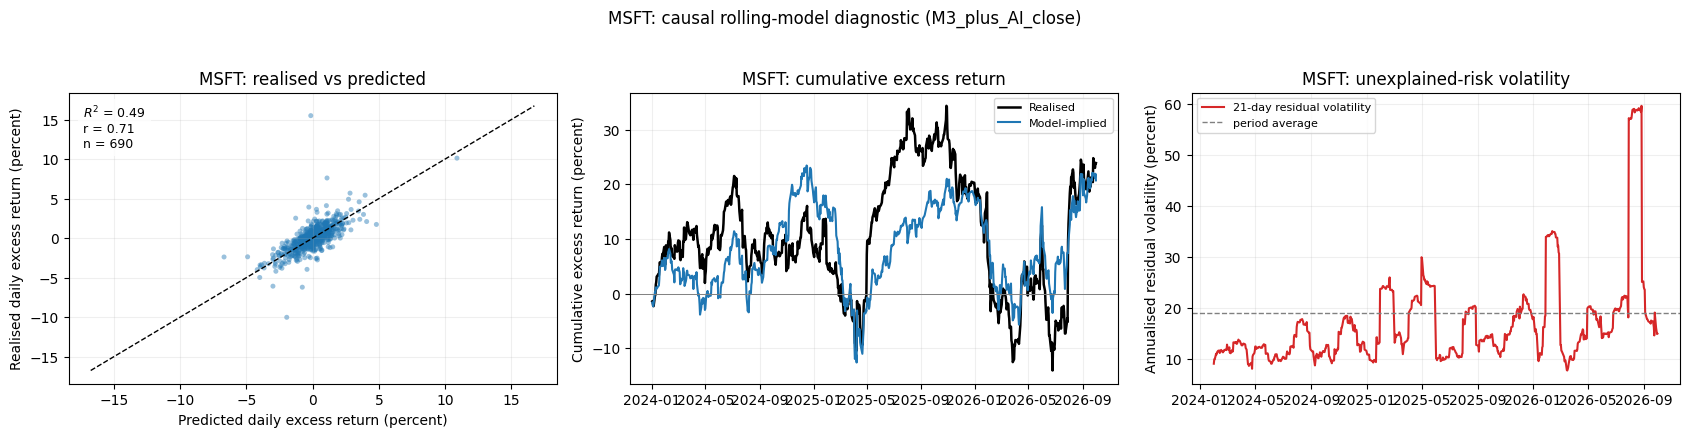

In [19]:
stock_diagnostic = plot_stock_prediction_diagnostics(res, 'MSFT')

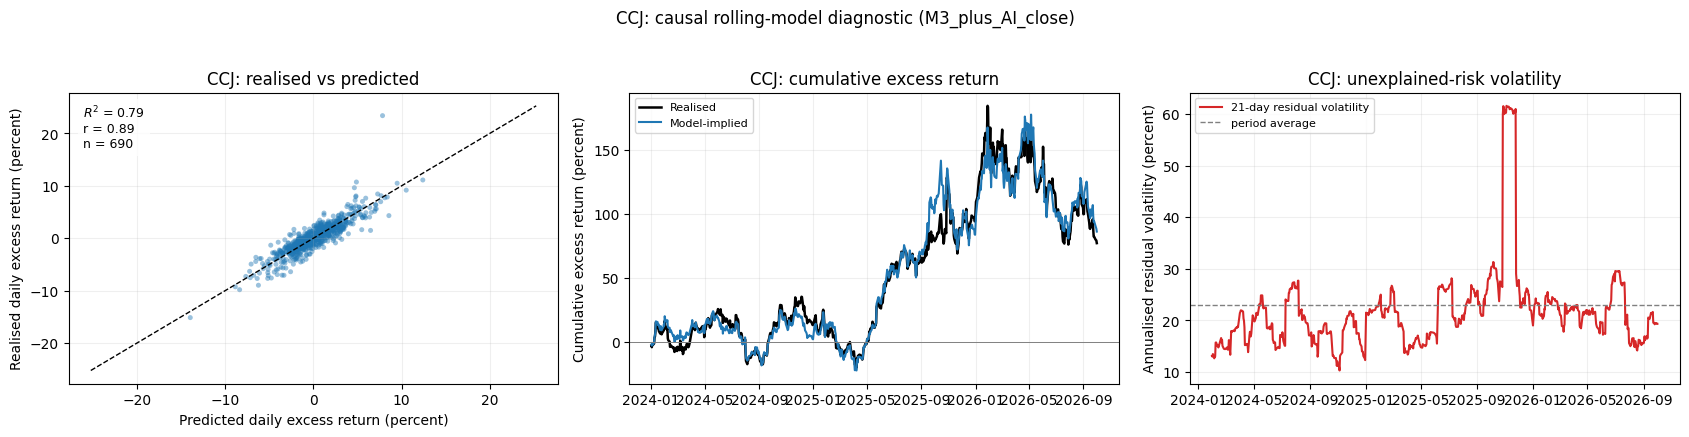

In [21]:
stock_diagnostic = plot_stock_prediction_diagnostics(res, 'CCJ')

## 13. AI-factor validation: AI-close names versus non-AI placebo controls

This is a pre-declared specificity check. It compares the incremental holdout fit from M2 to M3, where M3 adds the AI-close block (`SEMI`, `SOFT`, `ROBO`, `MOM`). A genuine AI-related signal should improve fit more for the AI-close portfolio and stocks than for mature, unrelated control companies. This is evidence of specificity, not proof of causation; direct ETF holdings are flagged because they can create mechanical fit.


In [ ]:
def ai_factor_placebo_test(results, base_model='M2_plus_adjacent', close_model='M3_plus_AI_close'):
    """Compare the M2-to-M3 holdout R2 gain for AI-close names and non-AI controls."""
    if base_model not in MODELS or close_model not in MODELS:
        raise KeyError('Choose model names present in MODELS.')
    added = [f for f in MODELS[close_model] if f not in MODELS[base_model]]
    target_info = results['targets'].copy()
    o = results['oos']
    m3 = o[(o['period'] == 'holdout') & (o['model'] == close_model)].copy()
    m2 = o[(o['period'] == 'holdout') & (o['model'] == base_model)][['target', 'r2_oos']].rename(columns={'r2_oos': 'r2_base'})
    d = m3.merge(m2, on='target', how='inner').merge(target_info, on='target', how='left')
    d['increment'] = d['r2_oos'] - d['r2_base']

    # Flag an ETF-membership overlap with any added factor: useful context, not a causal test.
    held = results['static_coef']
    held = held[held['factor'].isin(added)].groupby('target')['held'].any() if len(held) else pd.Series(dtype=bool)
    d['direct_factor_holding'] = d['target'].map(held).fillna(False)
    stocks = d[d['test_group'].isin(['AI_close', 'non_AI_control']) & (d['kind'] == 'stock')].copy()
    portfolios = d[d['target'].isin(['AI_close_test', 'non_AI_control_test'])].copy()
    if len(portfolios) < 2:
        raise ValueError('Validation portfolios are missing. Run notebooks 01--04 from the top after downloading the control stocks.')

    print('AI-factor specificity check: holdout incremental R2 of M3 over M2')
    print('Added block:', ', '.join(added))
    print('A positive AI-close gain with a near-zero/smaller control gain supports specificity. It does not establish causation.')
    display(portfolios[['target', 'n_days', 'r2_base', 'r2_oos', 'increment', 'd_lo', 'd_hi', 'sig']].round(3))
    display(stocks[['target', 'test_group', 'r2_base', 'r2_oos', 'increment', 'd_lo', 'd_hi', 'sig', 'direct_factor_holding']].sort_values(['test_group', 'increment'], ascending=[True, False]).round(3))

    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
    p = portfolios.set_index('target').reindex(['AI_close_test', 'non_AI_control_test'])
    x = np.arange(len(p))
    axs[0].errorbar(x, p['increment'], yerr=[p['increment'] - p['d_lo'], p['d_hi'] - p['increment']],
                    fmt='o', capsize=5, color='tab:blue')
    axs[0].axhline(0, color='grey', lw=1)
    axs[0].set_xticks(x); axs[0].set_xticklabels(['AI-close portfolio', 'Non-AI controls'])
    axs[0].set_ylabel('Incremental holdout $R^2$: M3 minus M2')
    axs[0].set_title('Portfolio placebo comparison (95% block-bootstrap CI)')
    axs[0].grid(axis='y', alpha=0.25)

    colours = {'AI_close': 'tab:blue', 'non_AI_control': 'tab:orange'}
    for j, group in enumerate(['AI_close', 'non_AI_control']):
        s = stocks[stocks['test_group'] == group].sort_values('increment')
        yy = np.arange(len(s)) + (0.08 if j else -0.08)
        axs[1].scatter(s['increment'], yy, s=45, color=colours[group], label=group.replace('_', ' '))
        for y, (_, row) in zip(yy, s.iterrows()):
            mark = '*' if row['direct_factor_holding'] else ''
            axs[1].text(row['increment'], y + 0.12, f"{row['target']}{mark}", fontsize=8, ha='center')
    axs[1].axvline(0, color='grey', lw=1)
    axs[1].set_yticks([])
    axs[1].set_xlabel('Incremental holdout $R^2$: M3 minus M2')
    axs[1].set_title('Individual stocks (* = directly held by an added-factor ETF)')
    axs[1].legend(fontsize=8); axs[1].grid(axis='x', alpha=0.25)
    fig.suptitle('Does the AI-close factor block help AI-exposed assets more than controls?', y=1.03)
    fig.tight_layout(); plt.show()
    return portfolios, stocks

ai_placebo_portfolios, ai_placebo_stocks = ai_factor_placebo_test(res)
